In [2]:
import os
import pickle
import dill
import pprint
import itertools
import pathos
import pprint
import functools
from functools import partial
from pathlib import Path
import logging
import json

import pandas as pd
import numpy as np
from scipy import stats as st
from sklearn.feature_selection import mutual_info_regression as MI

import json
import plotly.graph_objects as go
from matplotlib import pyplot as plt
import seaborn as sns
sns.set()

import sys
sys.path.append('/Users/leonardo.tessarolo/git/bayesian_bss/')
from src import ContourLineGraphPlotter, MCMCGraphPlotter, MAPGradientAscentGraphPlotter, SignalGraphPlotter

In [3]:
# todo: gerar teste com numero alto de amostras e avaliar convergencia do histograma

# 1. Read and parse raw results

In [2]:
# Experiment name
EXPERIMENT_NAME = 'nobs_1k_nrealizations_100'

# Realization number
realization_number = 0

# Folder which will contain output directory tree
OUTPUT_DIR='./output'
base_output_path=Path(OUTPUT_DIR)

# Directory which holds experiments
experiment_dir = base_output_path / EXPERIMENT_NAME

# Directory which holds realization results
realization_dir = experiment_dir / str(realization_number)

# Read raw results
with (realization_dir/'results_raw.pkl').open('rb') as f:
        raw_results = dill.load(f)

# Read experiment configs
with (experiment_dir/'execution_config.pkl').open('rb') as f:
        execution_config = dill.load(f)


In [3]:
raw_results.keys()

dict_keys(['perfect_model', 'slightly_misspecified_model', 'largely_misspecified_model', 'results'])

In [4]:
execution_config.keys()

dict_keys(['general', 'contour', 'map', 'mcmc', 'sim'])

# 2. Signal plots

## 2.1. Perfect model

In [5]:
# Run perfect model
model_cfg = 'perfect_model'

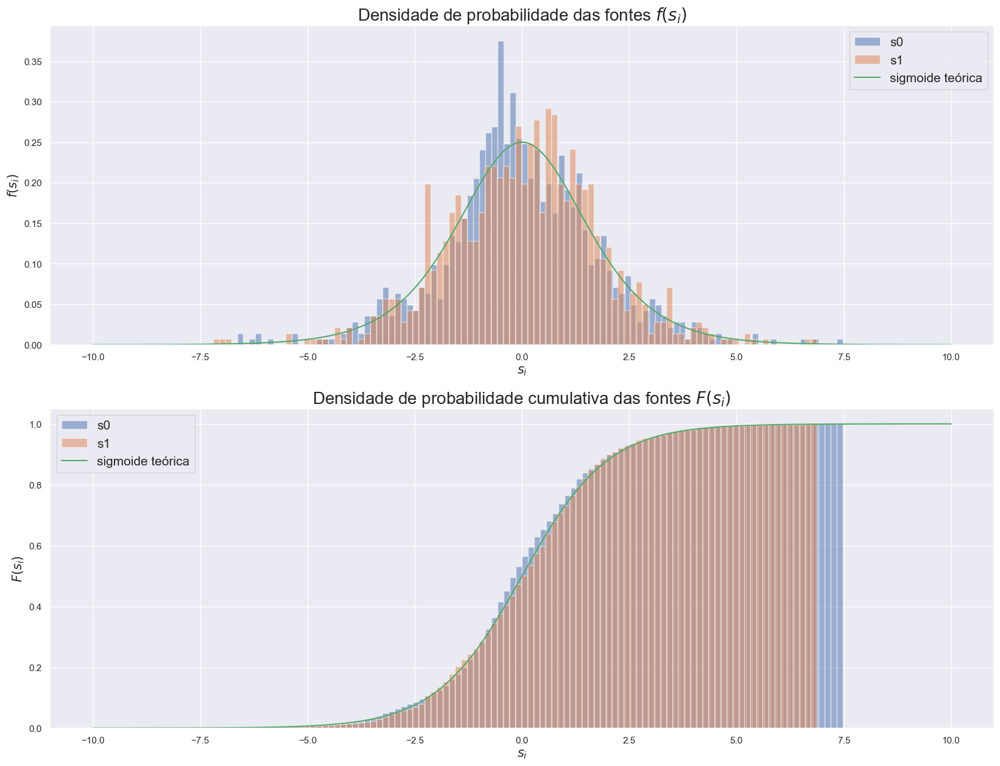

In [6]:
SignalGraphPlotter.plot_sources(
    s=raw_results[model_cfg]['s'],
    source_model=execution_config['sim']['source_model']
)

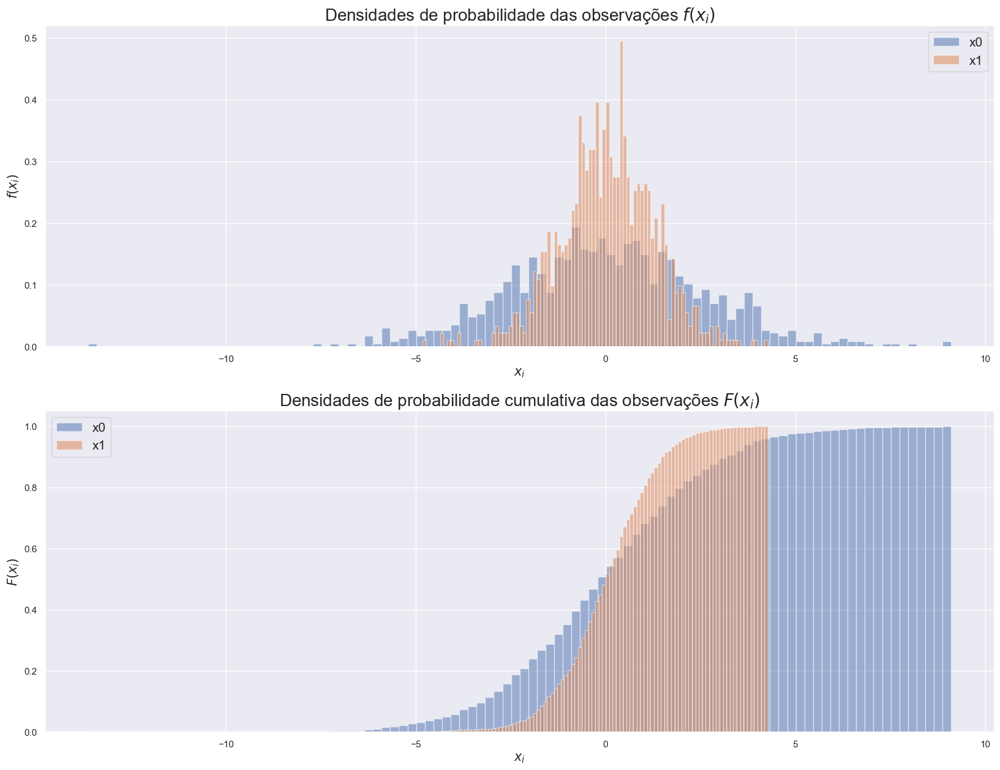

In [7]:
SignalGraphPlotter.plot_mixtures(
    x=raw_results[model_cfg]['x']
)

## 2.2. Slightly Misspecified Model

In [8]:
# Run perfect model
model_cfg = 'slightly_misspecified_model'

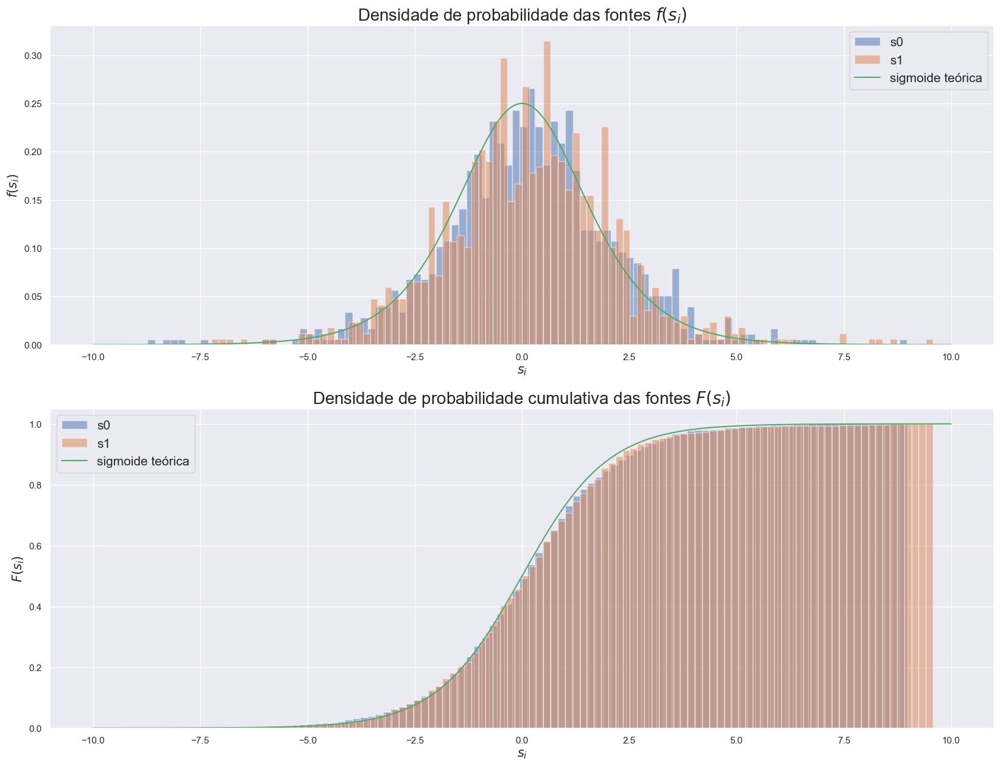

In [9]:
SignalGraphPlotter.plot_sources(
    s=raw_results[model_cfg]['s'],
    source_model=execution_config['sim']['source_model']
)

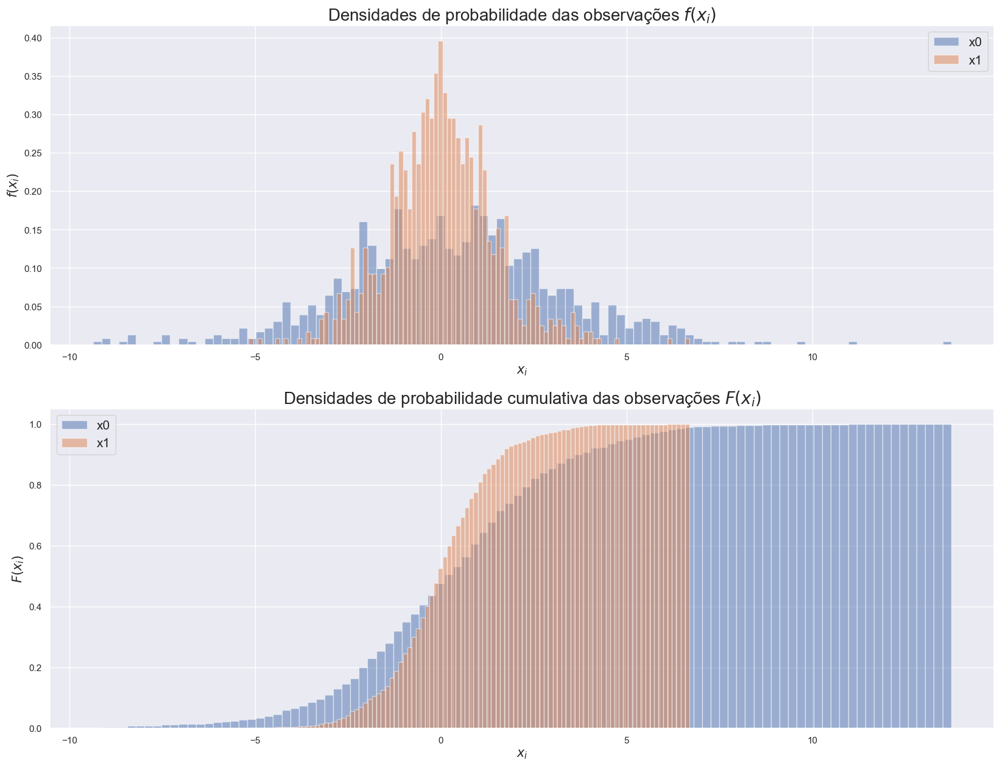

In [10]:
SignalGraphPlotter.plot_mixtures(
    x=raw_results[model_cfg]['x']
)

## 2.3. Largely misspecified model

In [11]:
# Run perfect model
model_cfg = 'largely_misspecified_model'

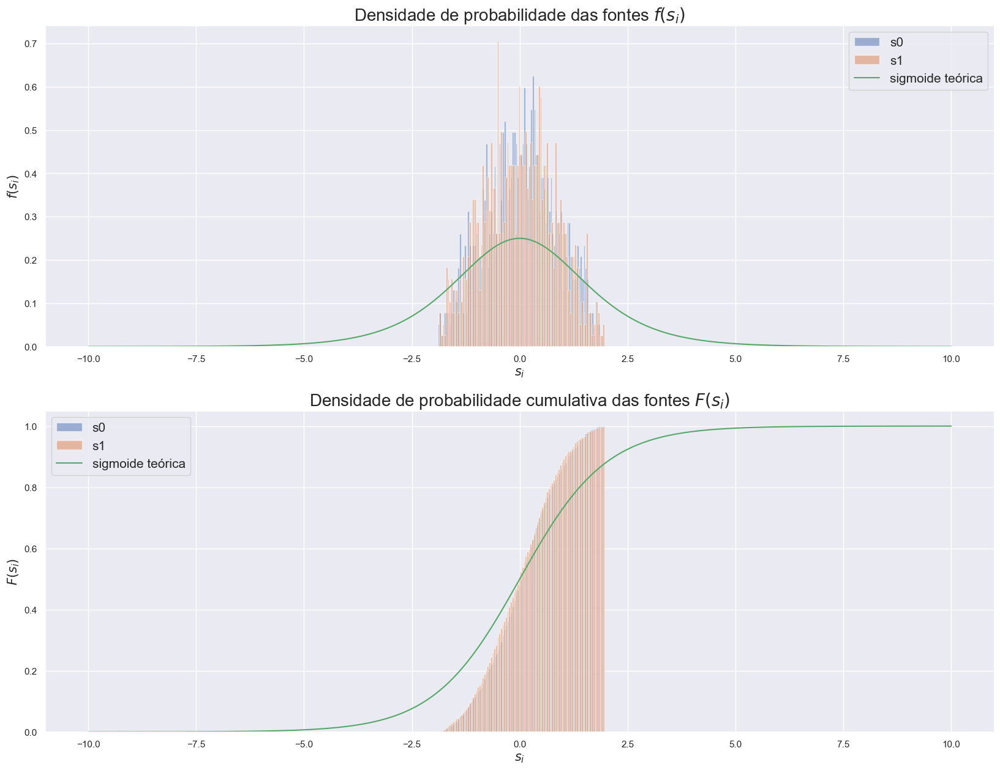

In [12]:
SignalGraphPlotter.plot_sources(
    s=raw_results[model_cfg]['s'],
    source_model=execution_config['sim']['source_model']
)

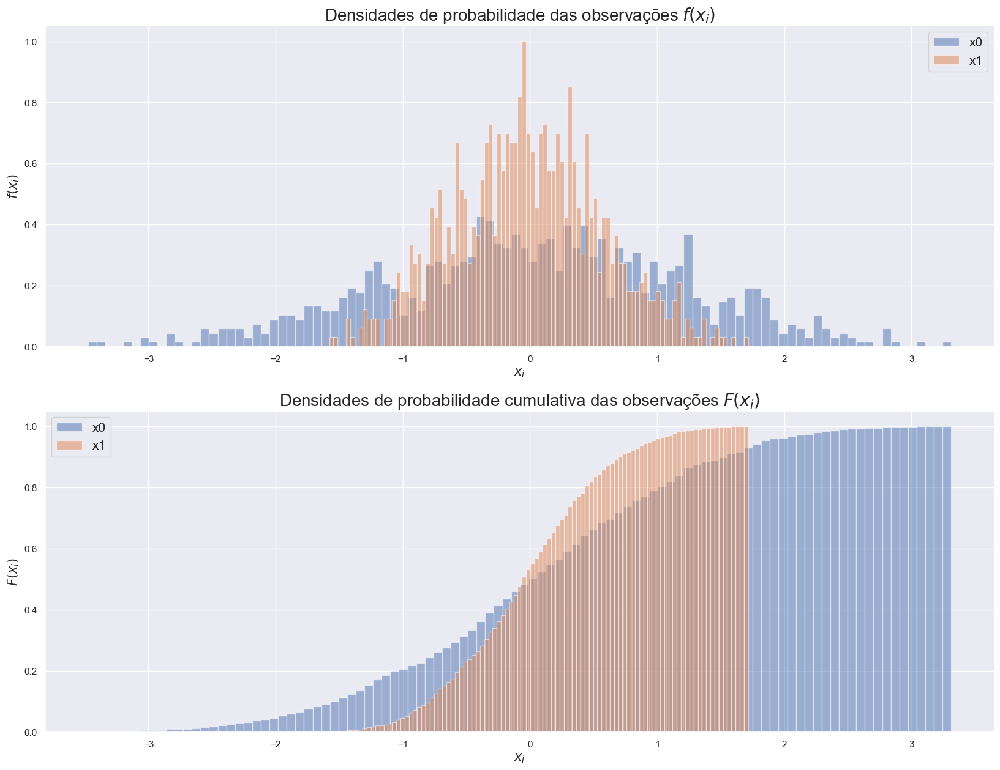

In [13]:
SignalGraphPlotter.plot_mixtures(
    x=raw_results[model_cfg]['x']
)

# 3. Plot Experiment Results

In [14]:
raw_results['results'].keys()

dict_keys(['i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x', 'xi', 'xii'])

In [15]:
# General quantities
A = execution_config['general']['A']
SAVE_GRAPHS = execution_config['general']['save_graphs']
NOBS = execution_config['general']['n_obs']
errors={}
SAVE_GRAPHS

True

## i.

In [16]:
# Test case
test_case='i'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-2.12206224, -1.13218572, -0.2772196 , ...,  1.40603267,
          3.06989017, -2.15950919],
        [-0.45218341,  0.24576018, -4.25206601, ...,  2.2474318 ,
         -0.33005412,  1.43724601]], shape=(2, 1000)),
 'x': array([[-2.57424565, -0.88642554, -4.52928562, ...,  3.65346447,
          2.73983605, -0.72226318],
        [ 0.83493941,  0.68897295, -1.98742321, ...,  0.42069956,
         -1.69997215,  1.7983776 ]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11938b8c0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x119554440>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x119554590>}

#### Parse MMSE

In [17]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [18]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.45976388 -1.12137996]
 [ 0.53702966  0.94028825]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.09227941920619714
----------------------------------------------------------------------------------------------------


In [19]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-3963.7015936052626)]

In [20]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.45976388, -1.12137996],
        [ 0.53702966,  0.94028825]])]

#### Parse MAP

In [21]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [22]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.55366887 -0.88305479]
 [ 0.43456217  1.12930433]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.12256956798974478
----------------------------------------------------------------------------------------------------


In [23]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-3.968120349813046)]

In [24]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.55366887, -0.88305479],
        [ 0.43456217,  1.12930433]])]

#### Parse contour line

In [25]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


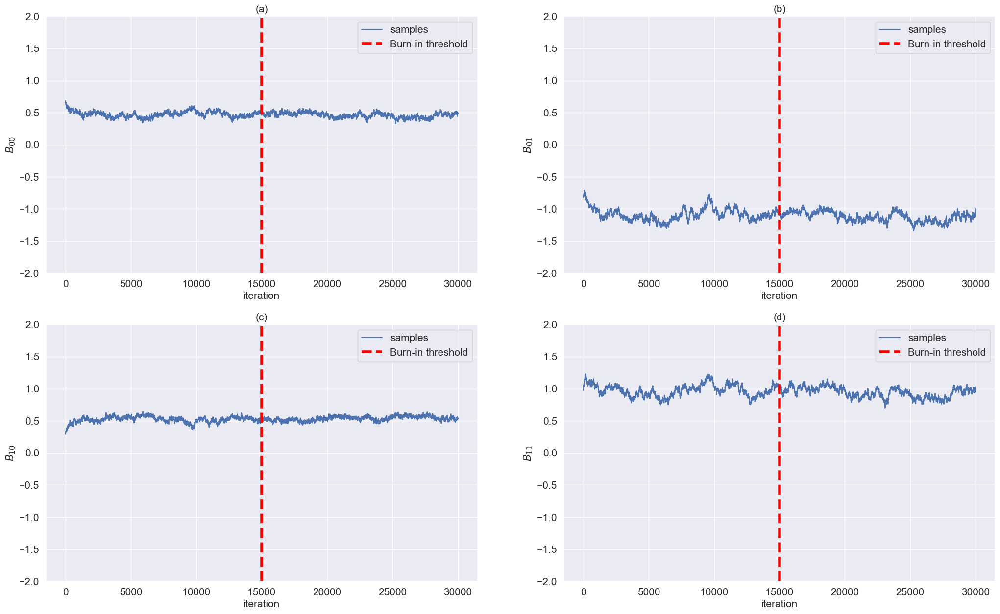

In [26]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


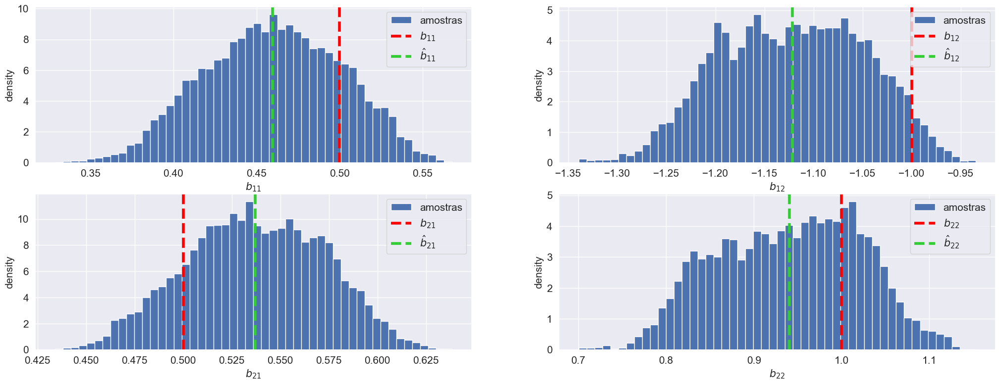

In [27]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


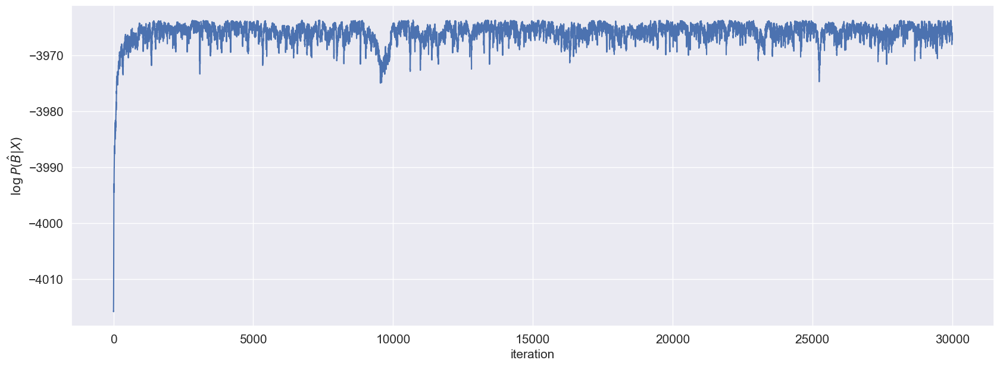

In [28]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


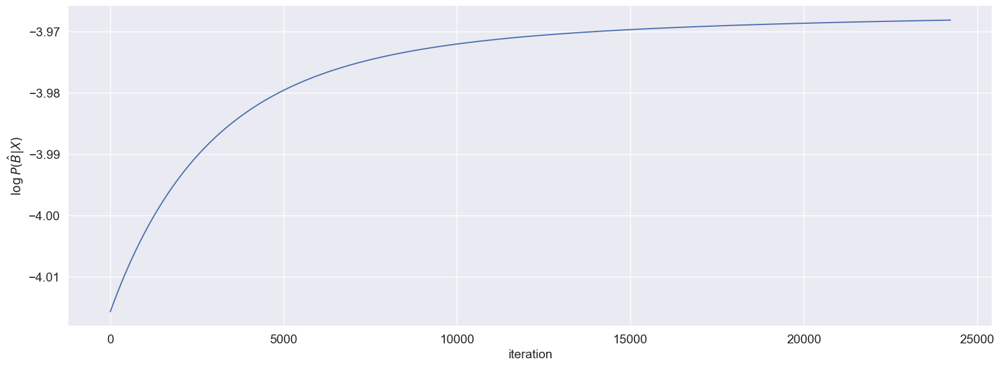

In [29]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


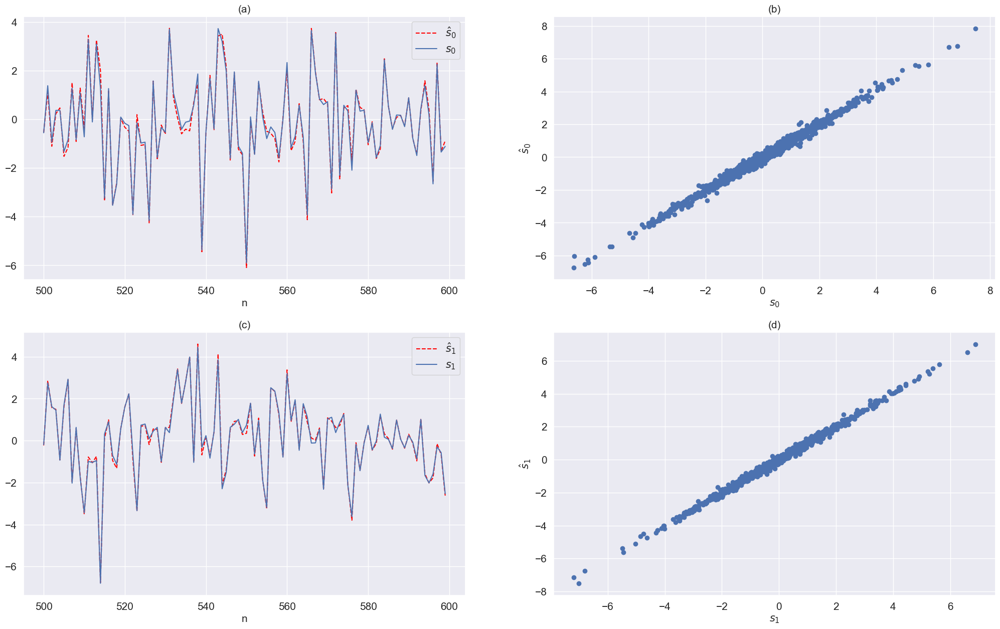

In [30]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


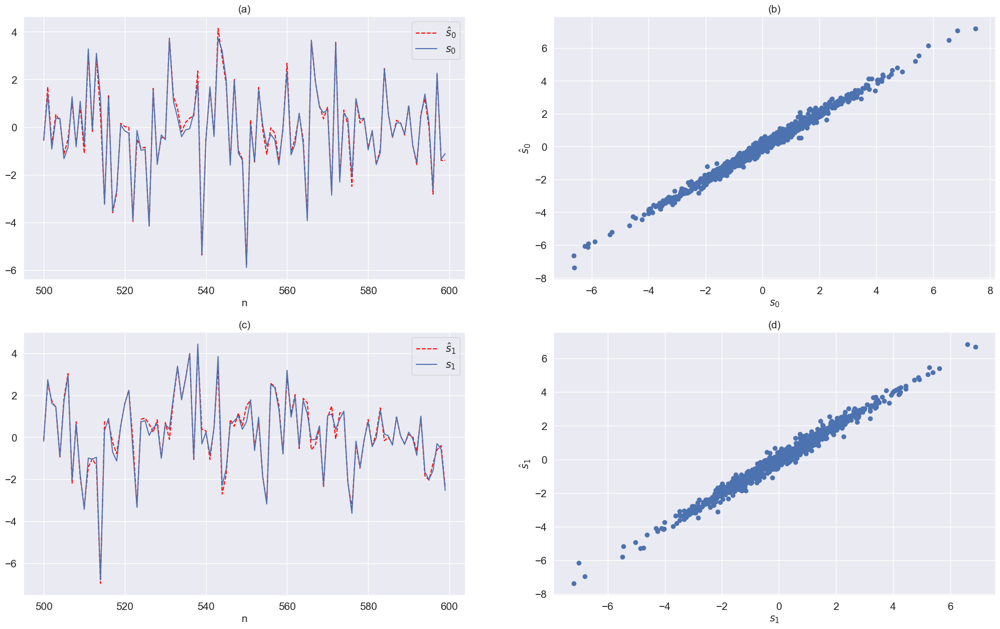

In [31]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


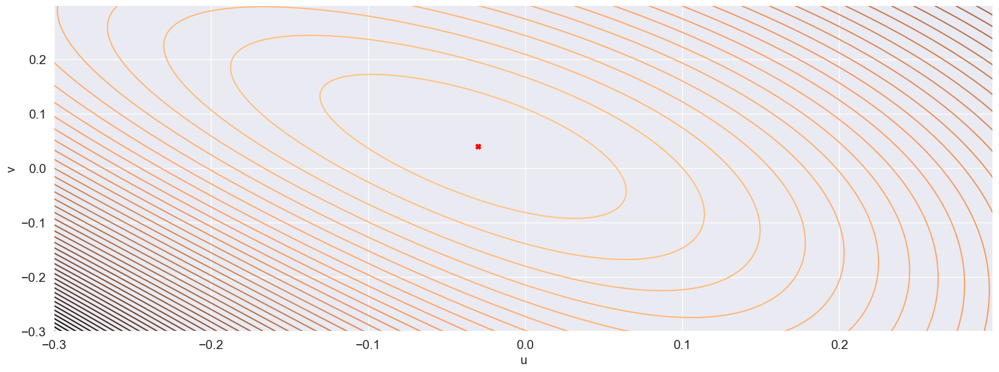

In [32]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [33]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.0034497835647905495), "
 "'s_map': np.float64(0.004846124252209122), 'B_mmse': "
 "np.float64(0.09227941920619714), 'B_map': np.float64(0.12256956798974478), "
 "'max_u_v': [np.float64(-0.03), np.float64(0.04)], 'u_v_norm': "
 'np.float64(0.05)}')


## ii.

In [34]:
# Test case
test_case='ii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-2.12206224, -1.13218572, -0.2772196 , ...,  1.40603267,
          3.06989017, -2.15950919],
        [-0.45218341,  0.24576018, -4.25206601, ...,  2.2474318 ,
         -0.33005412,  1.43724601]], shape=(2, 1000)),
 'x': array([[-2.57424565, -0.88642554, -4.52928562, ...,  3.65346447,
          2.73983605, -0.72226318],
        [ 0.83493941,  0.68897295, -1.98742321, ...,  0.42069956,
         -1.69997215,  1.7983776 ]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11954c7d0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x11954ccd0>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x11954ce10>}

#### Parse MMSE

In [35]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [36]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.45636468 -1.13288404]
 [ 0.53908735  0.93146806]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.1015611287395964
----------------------------------------------------------------------------------------------------


In [37]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-3963.696901012237)]

In [38]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.45636468, -1.13288404],
        [ 0.53908735,  0.93146806]])]

#### Parse MAP

In [39]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [40]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.55365268 -0.88310336]
 [ 0.43458491  1.12927846]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.12253243046990671
----------------------------------------------------------------------------------------------------


In [41]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-3.9681189158010417)]

In [42]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.55365268, -0.88310336],
        [ 0.43458491,  1.12927846]])]

#### Parse contour line

In [43]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


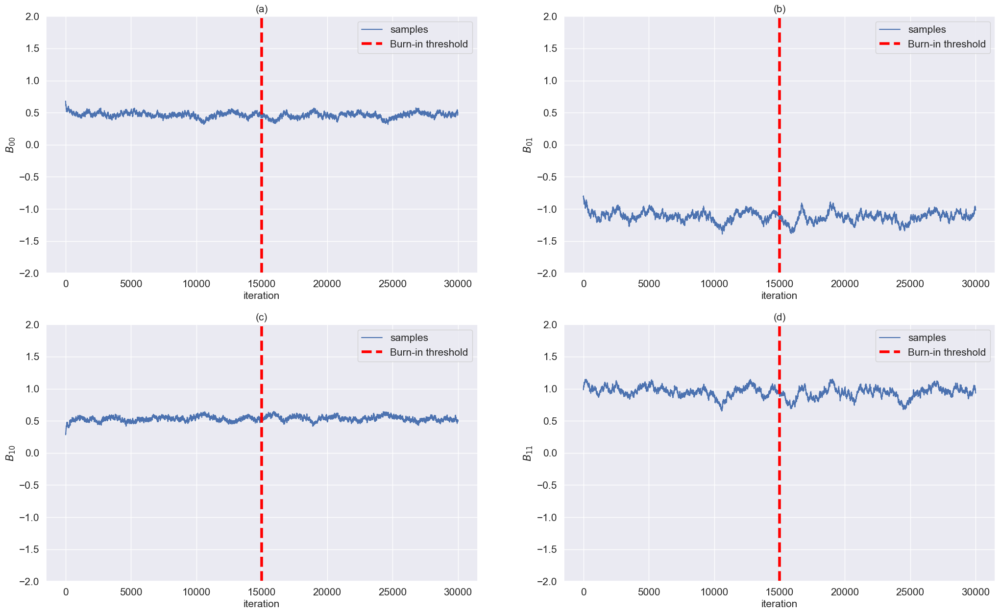

In [44]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


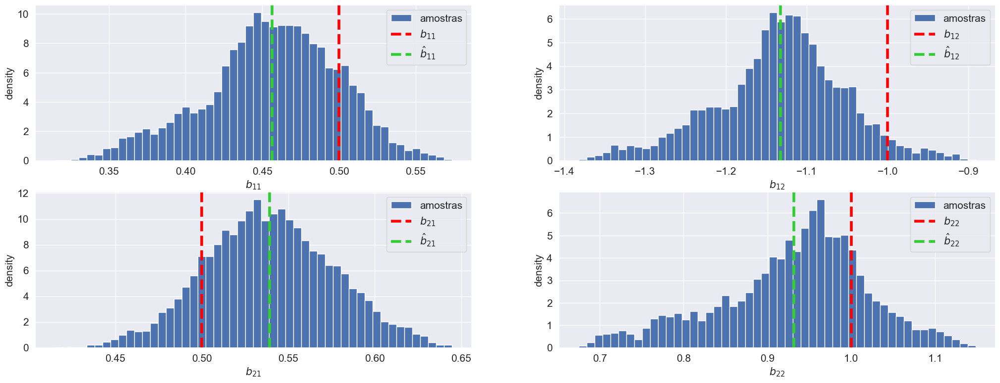

In [45]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


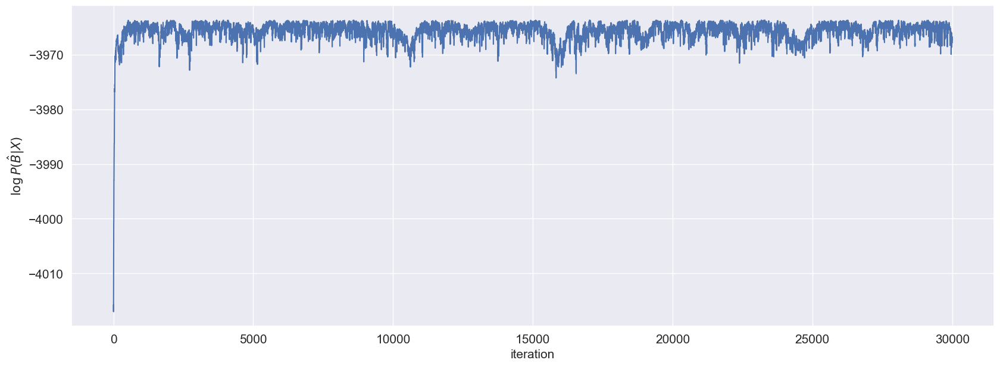

In [46]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


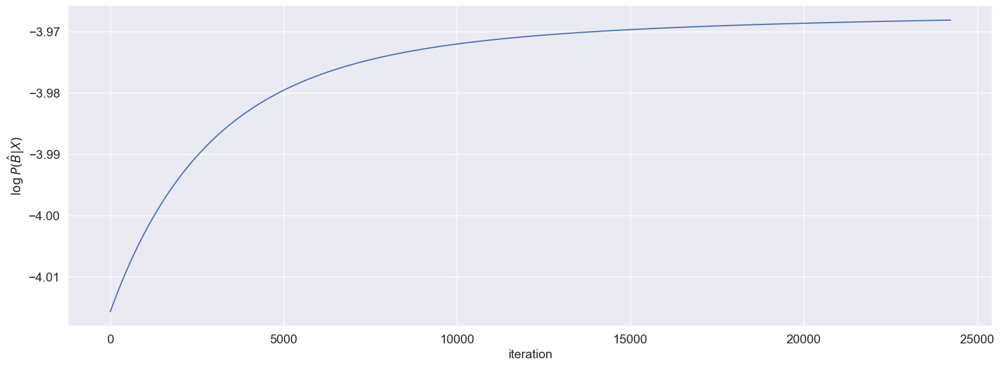

In [47]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


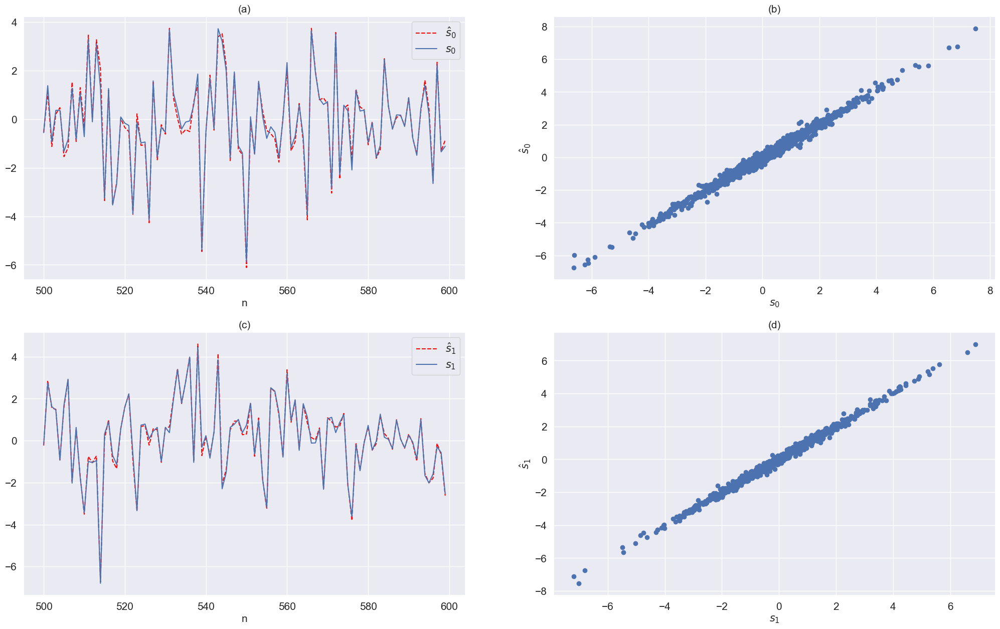

In [48]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


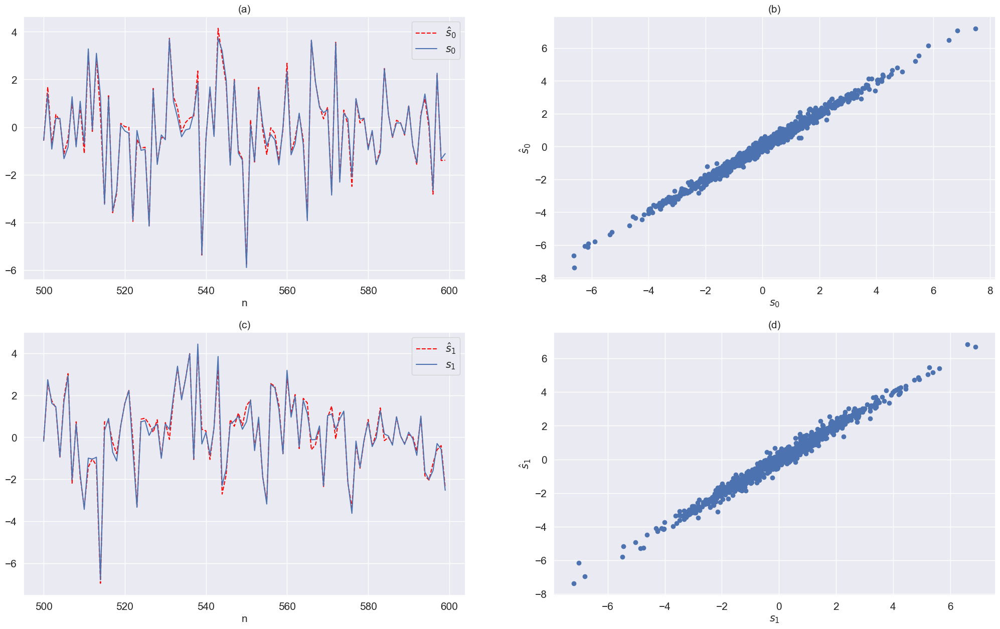

In [49]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


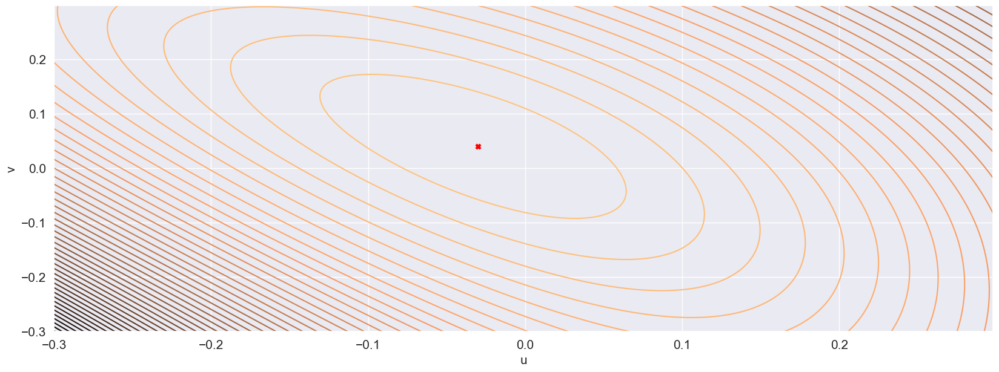

In [50]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [51]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.003765259047728241), "
 "'s_map': np.float64(0.004844609128674674), 'B_mmse': "
 "np.float64(0.1015611287395964), 'B_map': np.float64(0.12253243046990671), "
 "'max_u_v': [np.float64(-0.03), np.float64(0.04)], 'u_v_norm': "
 'np.float64(0.05)}')


## iii.

In [52]:
# Test case
test_case='iii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-2.12206224, -1.13218572, -0.2772196 , ...,  1.40603267,
          3.06989017, -2.15950919],
        [-0.45218341,  0.24576018, -4.25206601, ...,  2.2474318 ,
         -0.33005412,  1.43724601]], shape=(2, 1000)),
 'x': array([[-2.57424565, -0.88642554, -4.52928562, ...,  3.65346447,
          2.73983605, -0.72226318],
        [ 0.83493941,  0.68897295, -1.98742321, ...,  0.42069956,
         -1.69997215,  1.7983776 ]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11954cf50>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x11954d1d0>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x11954d310>}

#### Parse MMSE

In [53]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [54]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.47972746 -1.07734401]
 [ 0.51868679  0.98559514]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.052724823462259846
----------------------------------------------------------------------------------------------------


In [55]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-3964.2346973975536)]

In [56]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.47972746, -1.07734401],
        [ 0.51868679,  0.98559514]])]

#### Parse MAP

In [57]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [58]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.54728756 -0.90716412]
 [ 0.44480071  1.12591678]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.10909924046815345
----------------------------------------------------------------------------------------------------


In [59]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-3.968856446219934)]

In [60]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.54728756, -0.90716412],
        [ 0.44480071,  1.12591678]])]

#### Parse contour line

In [61]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


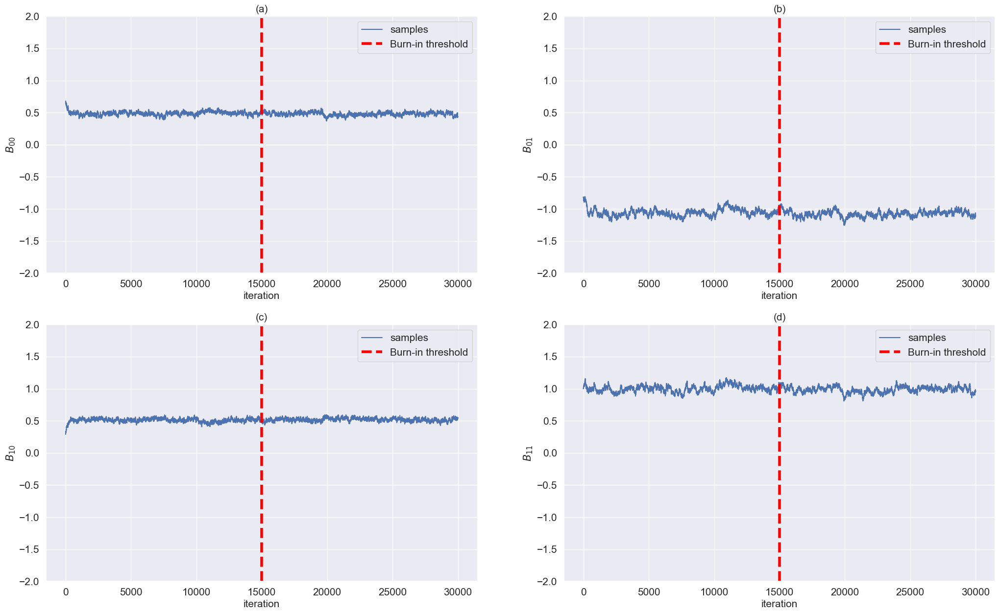

In [62]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


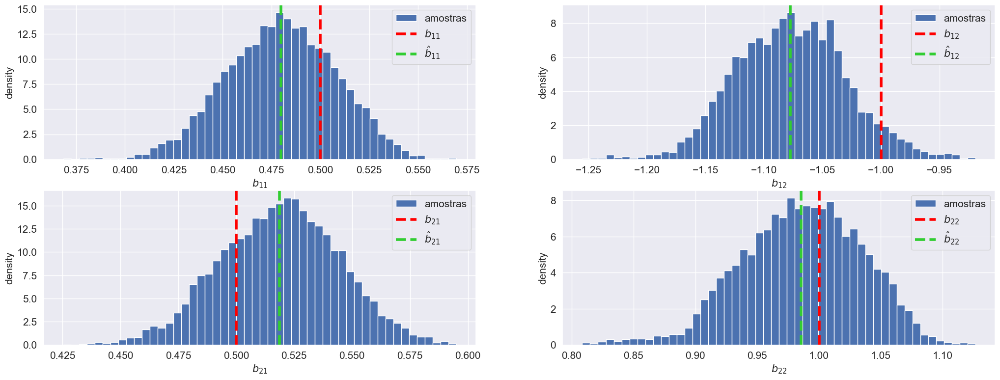

In [63]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


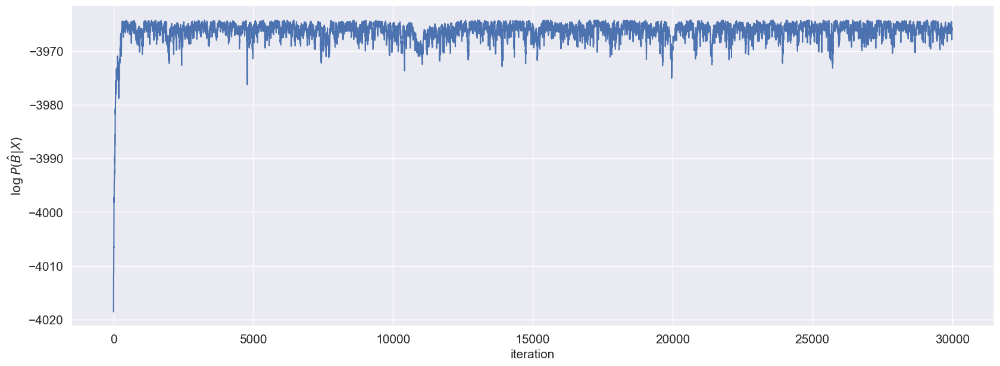

In [64]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


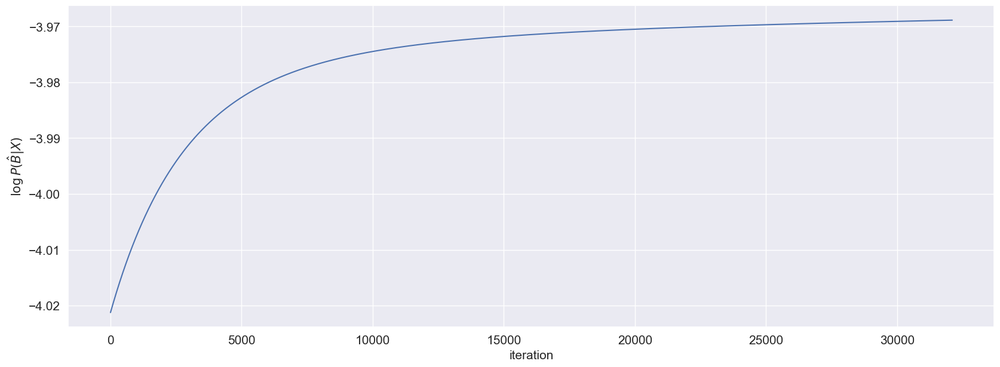

In [65]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


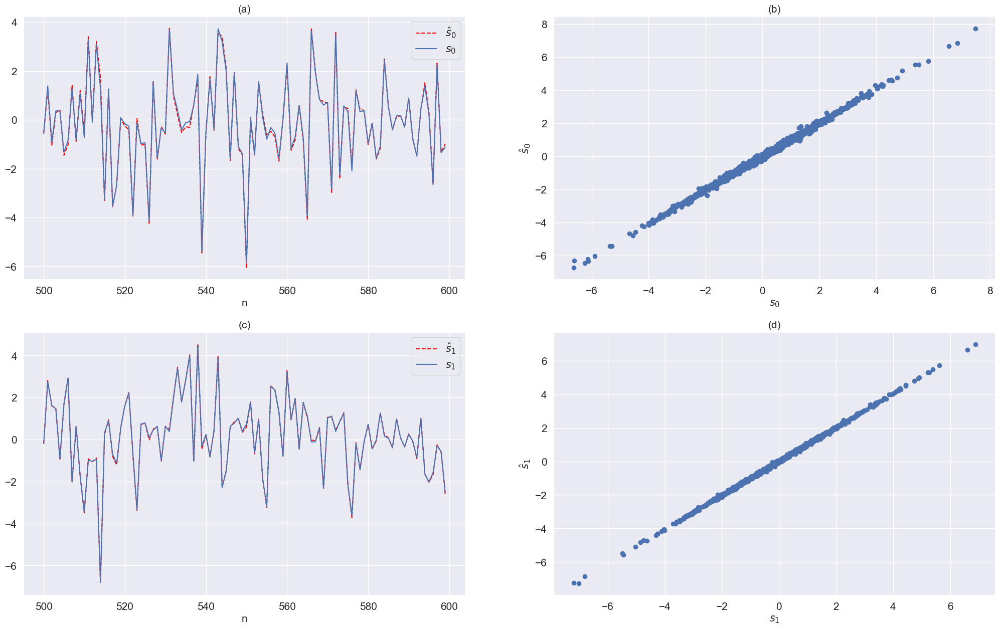

In [66]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


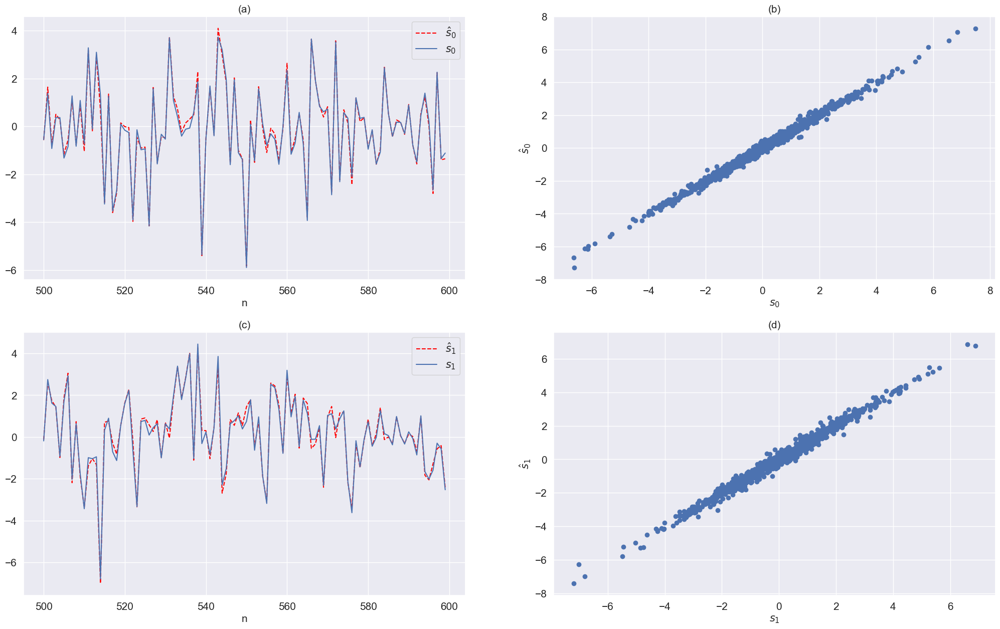

In [67]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


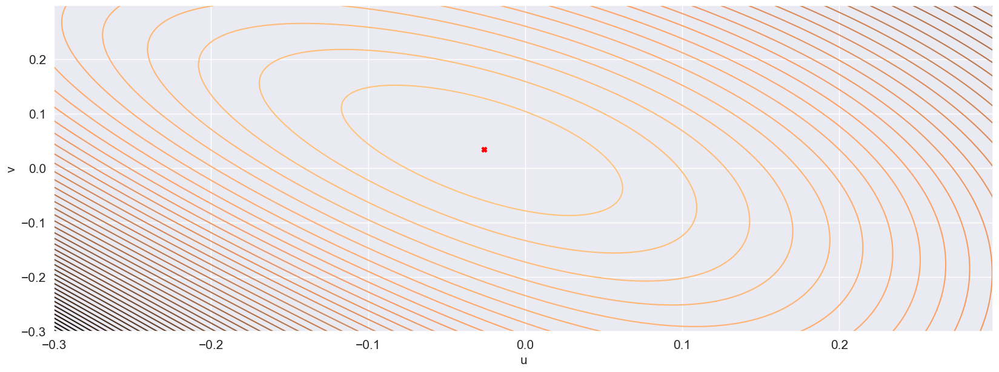

In [68]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [69]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.0018988974676508628), "
 "'s_map': np.float64(0.004257285549061974), 'B_mmse': "
 "np.float64(0.052724823462259846), 'B_map': np.float64(0.10909924046815345), "
 "'max_u_v': [np.float64(-0.026000000000000002), np.float64(0.034)], "
 "'u_v_norm': np.float64(0.0428018691180654)}")


## iv.

In [70]:
# Test case
test_case='iv'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-2.12206224, -1.13218572, -0.2772196 , ...,  1.40603267,
          3.06989017, -2.15950919],
        [-0.45218341,  0.24576018, -4.25206601, ...,  2.2474318 ,
         -0.33005412,  1.43724601]], shape=(2, 1000)),
 'x': array([[-2.57424565, -0.88642554, -4.52928562, ...,  3.65346447,
          2.73983605, -0.72226318],
        [ 0.83493941,  0.68897295, -1.98742321, ...,  0.42069956,
         -1.69997215,  1.7983776 ]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x1195116e0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x119511940>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x119511a70>}

#### Parse MMSE

In [71]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [72]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.6840272   0.2675394 ]
 [-0.13790231  1.36151466]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.9334097416502938
----------------------------------------------------------------------------------------------------


In [73]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-4001.1043660761243)]

In [74]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.6840272 ,  0.2675394 ],
        [-0.13790231,  1.36151466]])]

#### Parse MAP

In [75]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [76]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.57734458 -0.82735669]
 [ 0.39941182  1.09906464]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.1492912344117586
----------------------------------------------------------------------------------------------------


In [77]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-4.024041446975686)]

In [78]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.57734458, -0.82735669],
        [ 0.39941182,  1.09906464]])]

#### Parse contour line

In [79]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


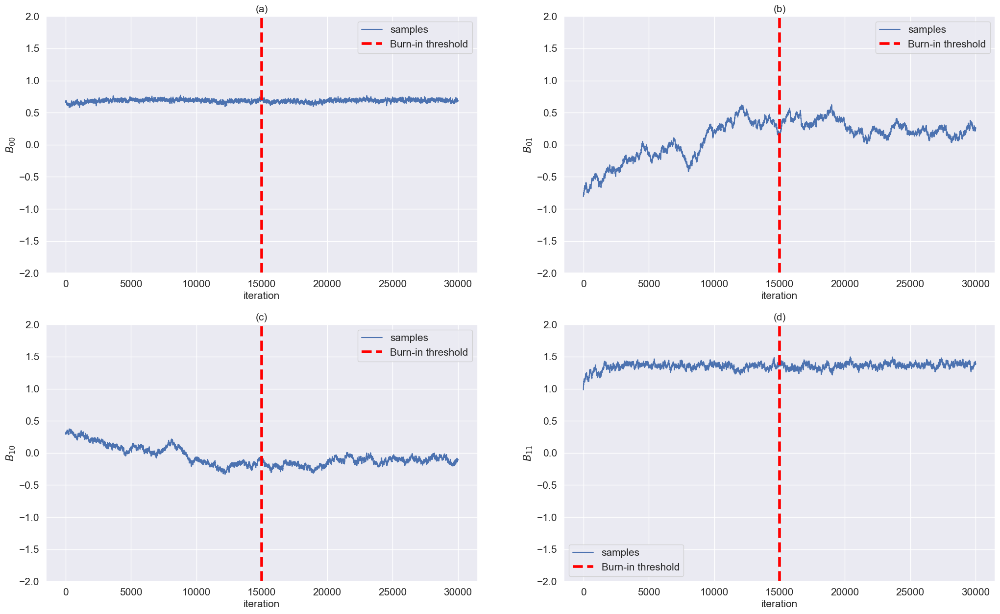

In [80]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


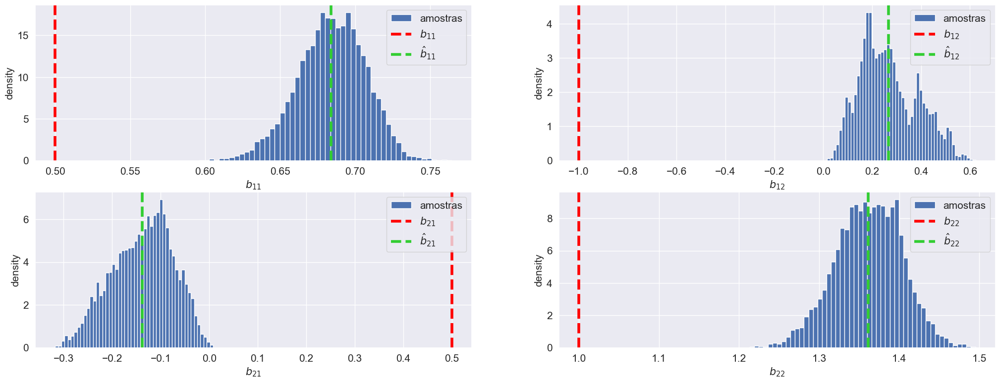

In [81]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


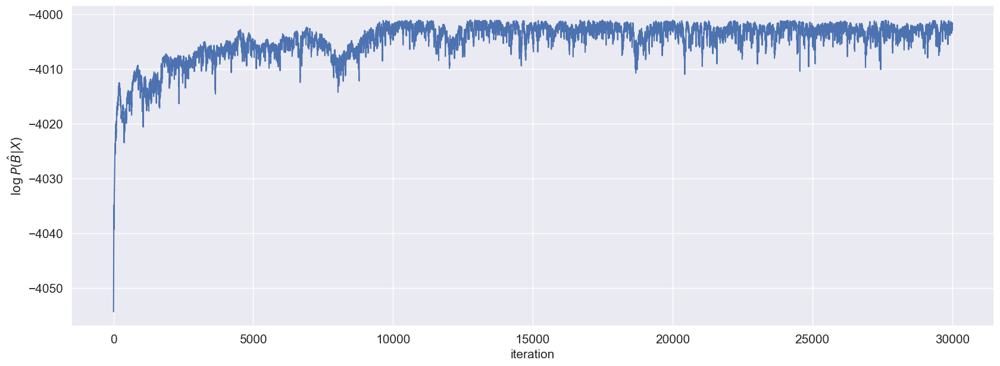

In [82]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


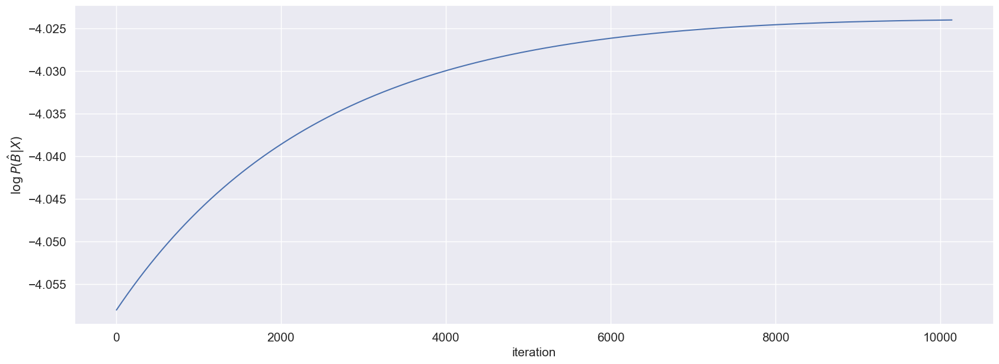

In [83]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


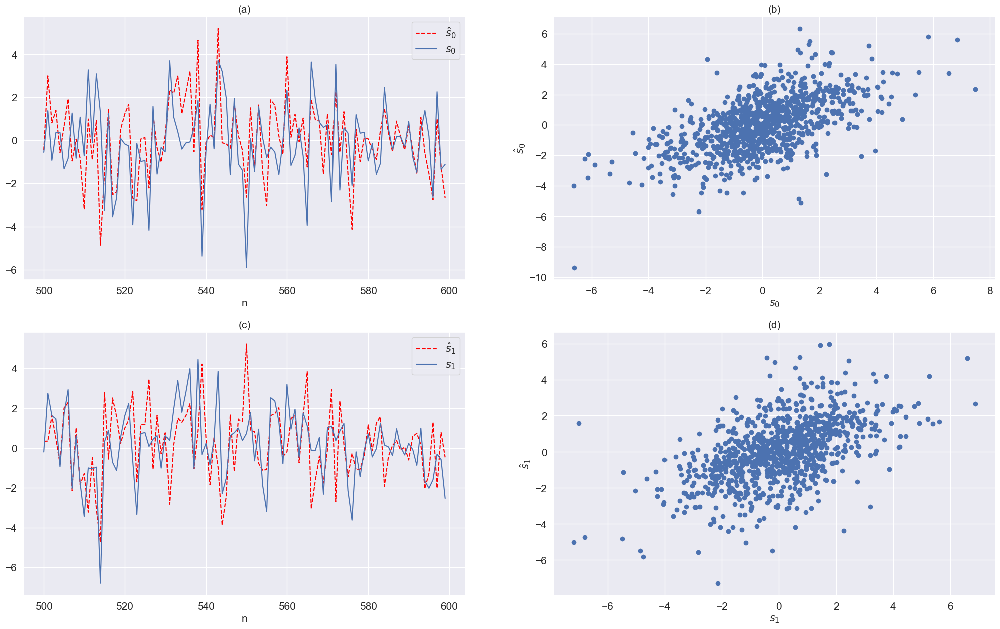

In [84]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


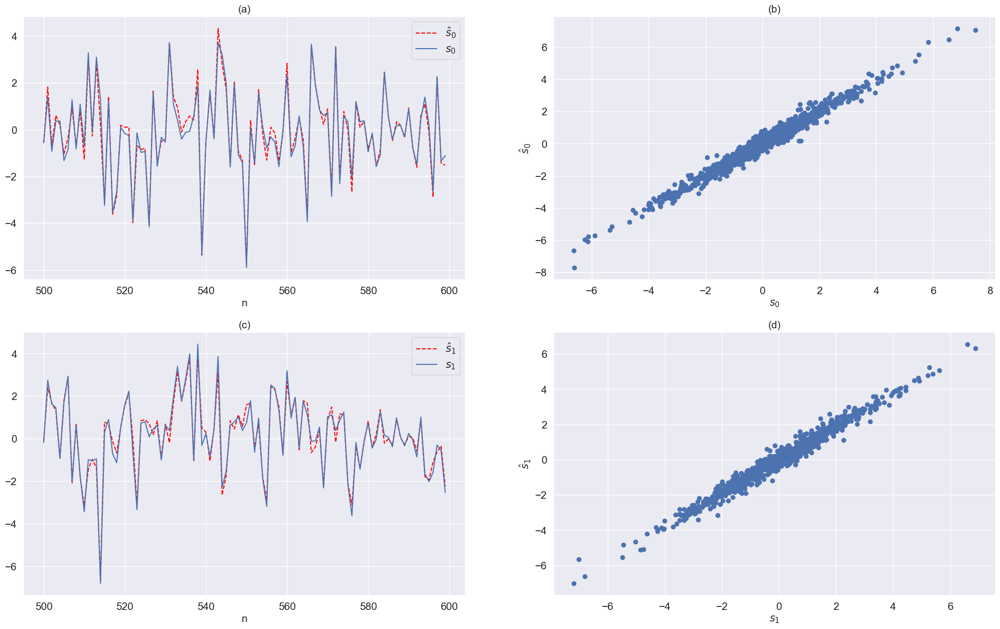

In [85]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


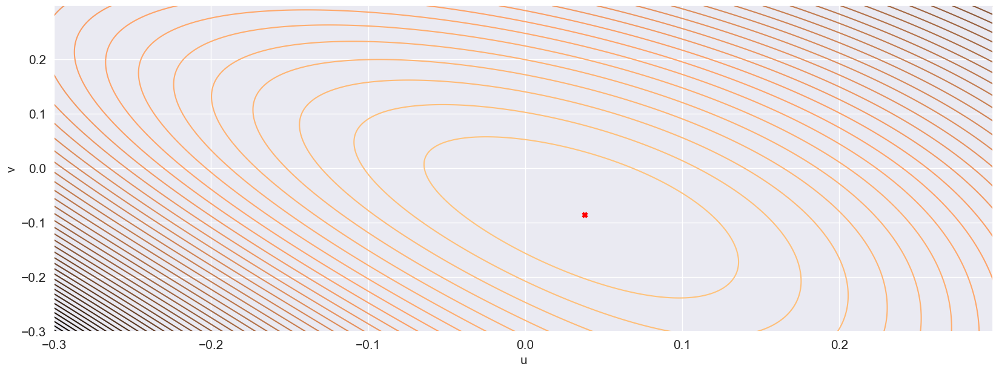

In [86]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [87]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.03731100301339054), "
 "'s_map': np.float64(0.0064541788101839855), 'B_mmse': "
 "np.float64(0.9334097416502938), 'B_map': np.float64(0.1492912344117586), "
 "'max_u_v': [np.float64(0.038), np.float64(-0.08600000000000001)], "
 "'u_v_norm': np.float64(0.09402127418834527)}")


## v.

In [88]:
# Test case
test_case='v'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[ 1.05192499,  0.38169569,  2.84148201, ...,  2.97151869,
          0.19921437,  1.22139494],
        [ 1.26592132, -1.52897239,  1.28811983, ...,  2.85701456,
         -1.00502702,  1.00604107]], shape=(2, 1000)),
 'x': array([[ 2.31784631, -1.14727671,  4.12960184, ...,  5.82853325,
         -0.80581265,  2.22743601],
        [ 0.10699817, -0.95533404, -0.77668109, ..., -0.05725206,
         -0.60212069, -0.10767693]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x119511ba0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x119511cd0>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x119511e00>}

#### Parse MMSE

In [89]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [90]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.42489187 -0.95321025]
 [ 0.47571632  0.86829112]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.10152327546254153
----------------------------------------------------------------------------------------------------


In [91]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-4200.754154728539)]

In [92]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.42489187, -0.95321025],
        [ 0.47571632,  0.86829112]])]

#### Parse MAP

In [93]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [94]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.50268344 -0.77955424]
 [ 0.39279337  1.01707996]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.15542010079031132
----------------------------------------------------------------------------------------------------


In [95]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-4.205036673337589)]

In [96]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.50268344, -0.77955424],
        [ 0.39279337,  1.01707996]])]

#### Parse contour line

In [97]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


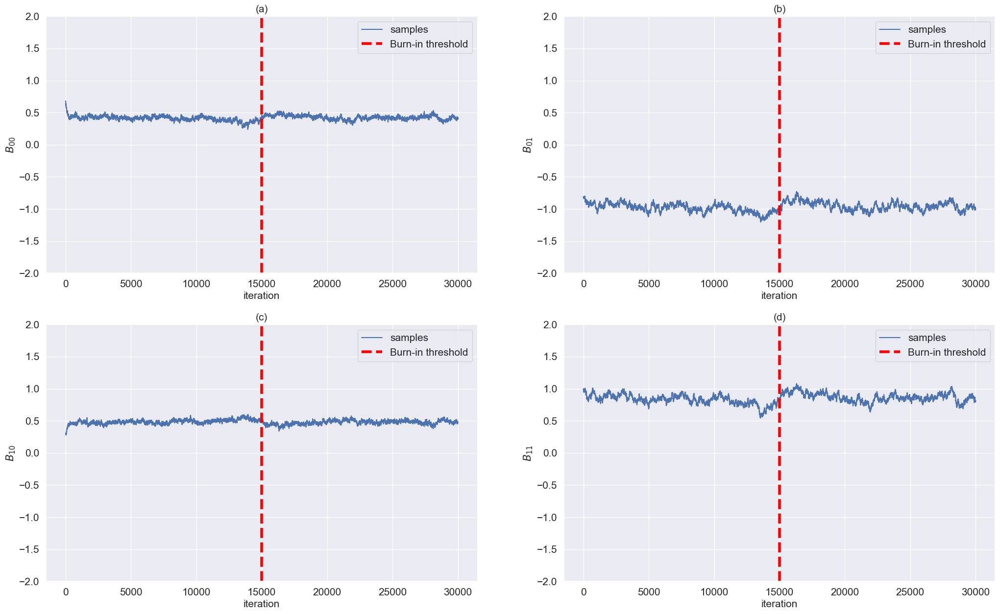

In [98]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


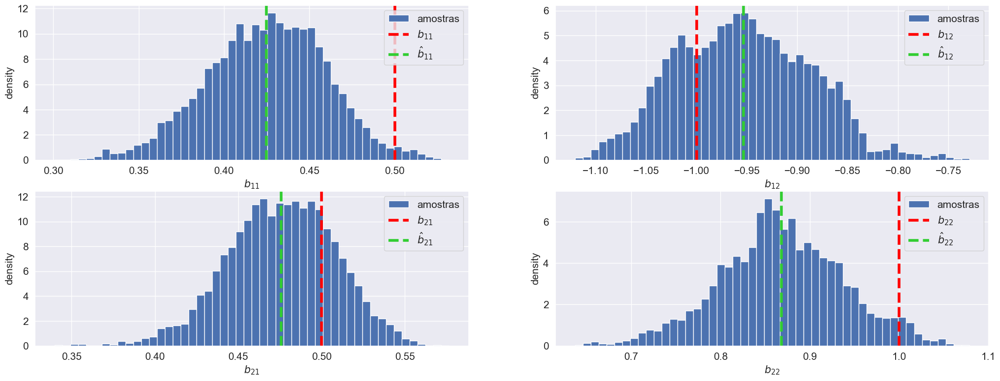

In [99]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


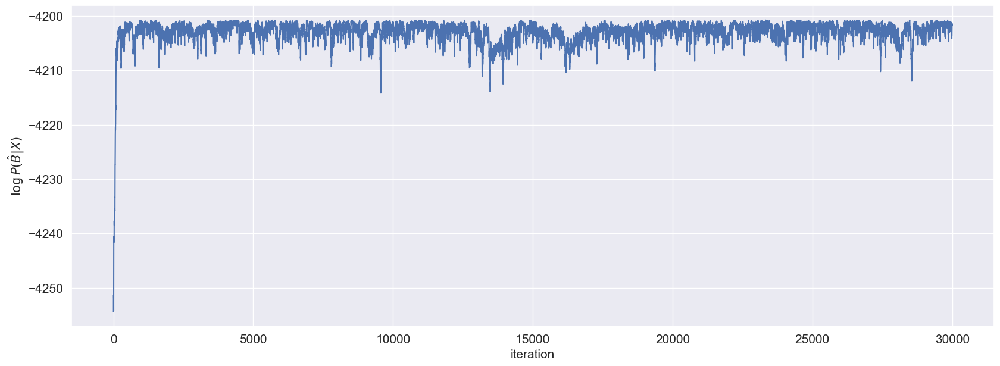

In [100]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


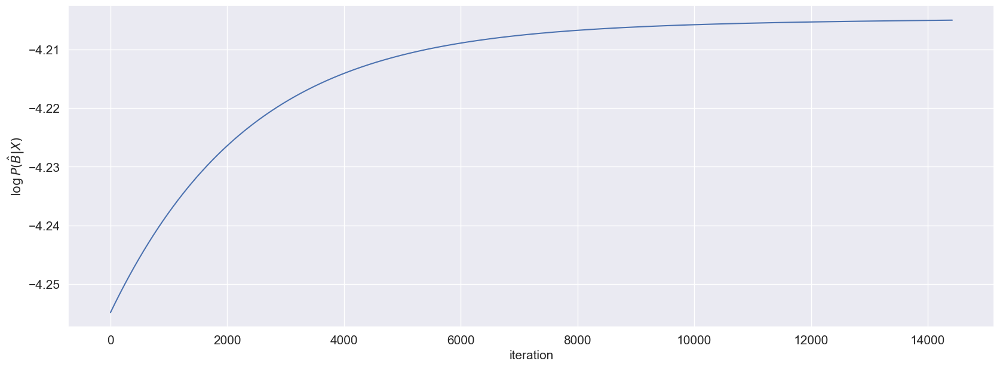

In [101]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


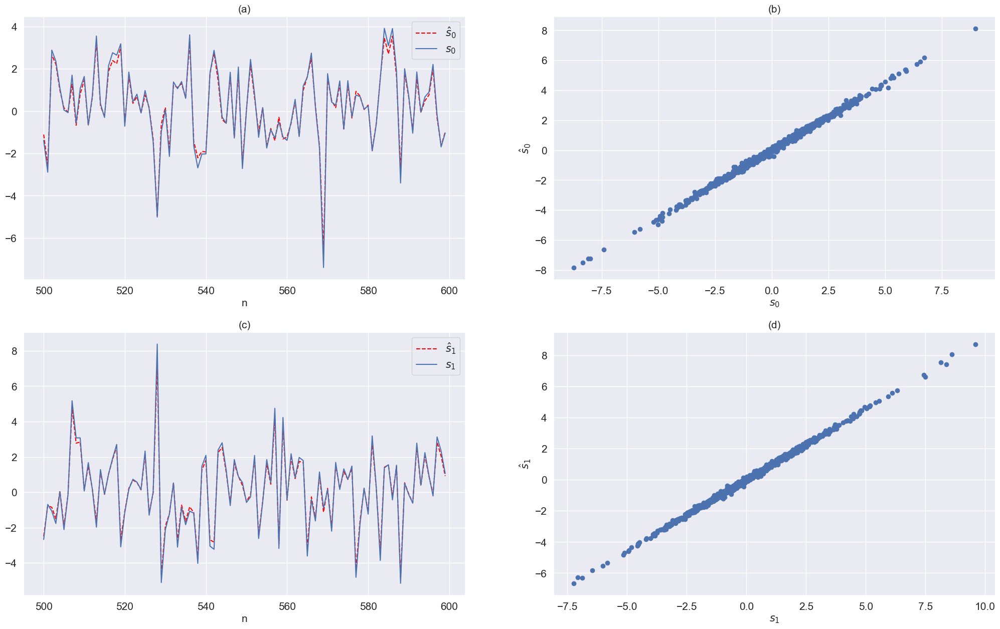

In [102]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


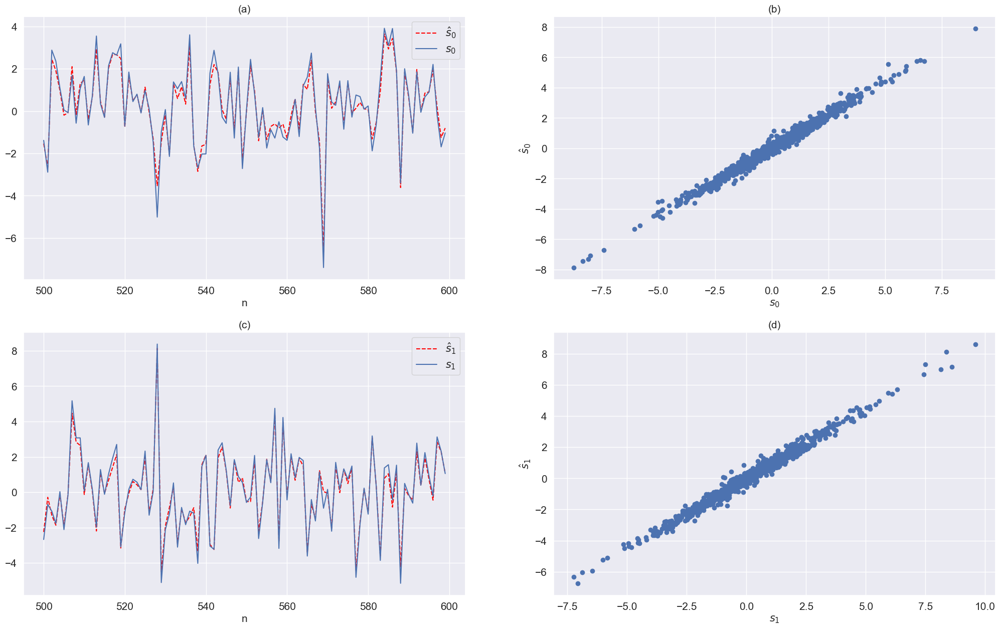

In [103]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


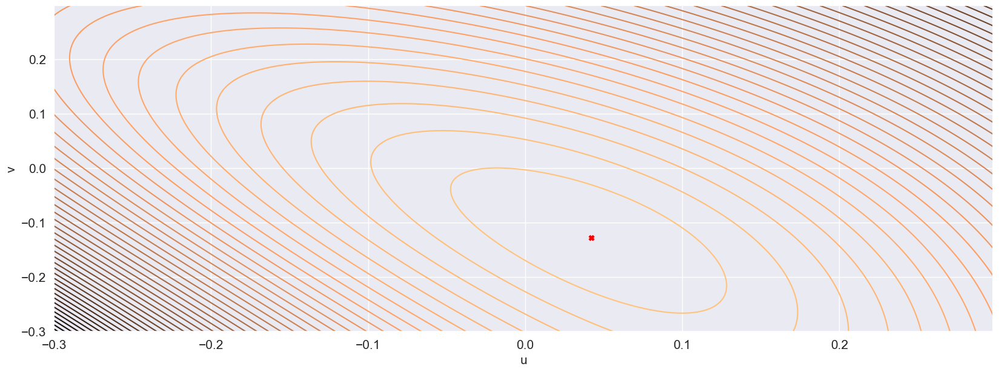

In [104]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [105]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.004770241843648826), "
 "'s_map': np.float64(0.006967436832505245), 'B_mmse': "
 "np.float64(0.10152327546254153), 'B_map': np.float64(0.15542010079031132), "
 "'max_u_v': [np.float64(0.042), np.float64(-0.128)], 'u_v_norm': "
 'np.float64(0.13471451295239129)}')


## vi.

In [106]:
# Test case
test_case='vi'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[ 1.05192499,  0.38169569,  2.84148201, ...,  2.97151869,
          0.19921437,  1.22139494],
        [ 1.26592132, -1.52897239,  1.28811983, ...,  2.85701456,
         -1.00502702,  1.00604107]], shape=(2, 1000)),
 'x': array([[ 2.31784631, -1.14727671,  4.12960184, ...,  5.82853325,
         -0.80581265,  2.22743601],
        [ 0.10699817, -0.95533404, -0.77668109, ..., -0.05725206,
         -0.60212069, -0.10767693]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x10e68c5f0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x107f8ab10>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x107f8ad50>}

#### Parse MMSE

In [107]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [108]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.40493462 -0.9930373 ]
 [ 0.49095305  0.82253798]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.12753120431408813
----------------------------------------------------------------------------------------------------


In [109]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-4200.7691563006765)]

In [110]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.40493462, -0.9930373 ],
        [ 0.49095305,  0.82253798]])]

#### Parse MAP

In [111]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [112]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.50267085 -0.77958681]
 [ 0.39281201  1.01706867]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.15539590008506649
----------------------------------------------------------------------------------------------------


In [113]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-4.2050358321547465)]

In [114]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.50267085, -0.77958681],
        [ 0.39281201,  1.01706867]])]

#### Parse contour line

In [115]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


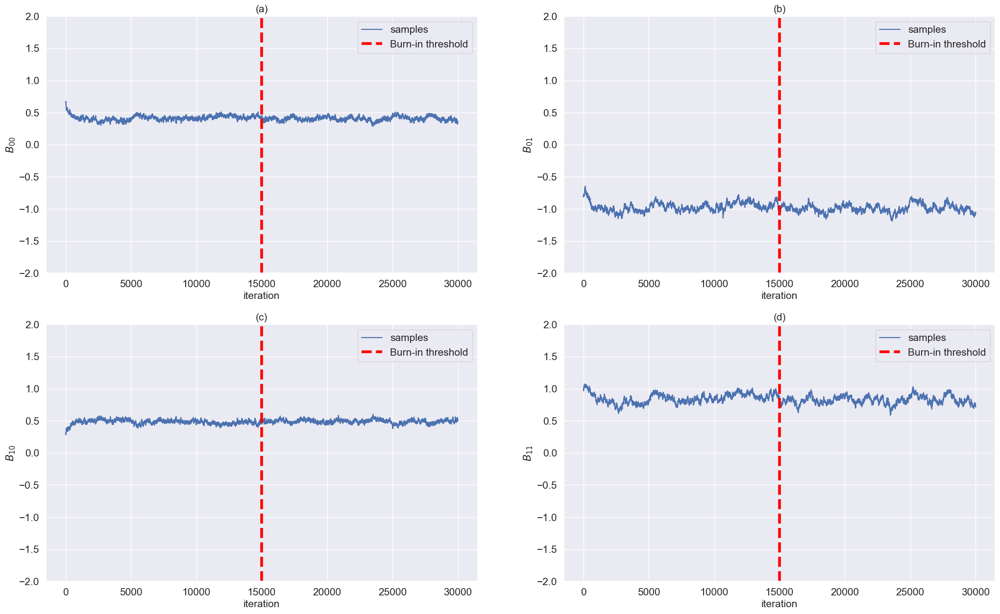

In [116]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


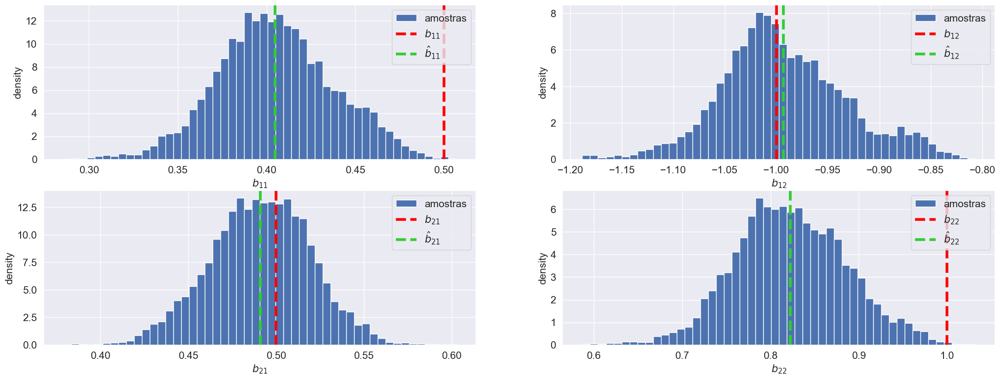

In [117]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


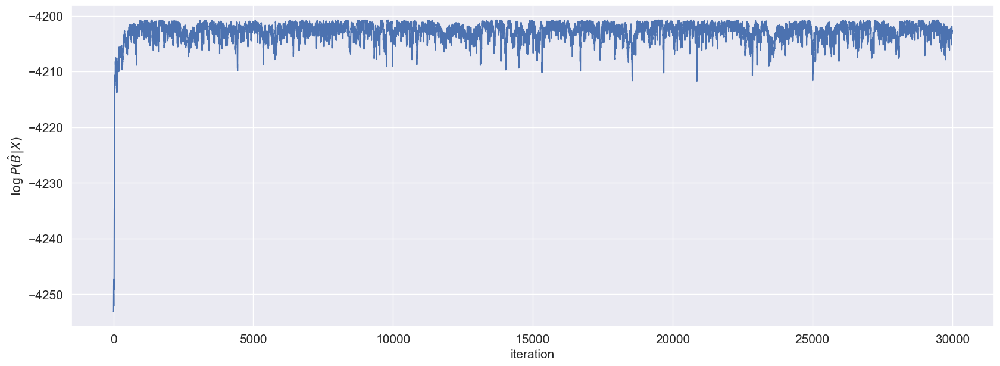

In [118]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


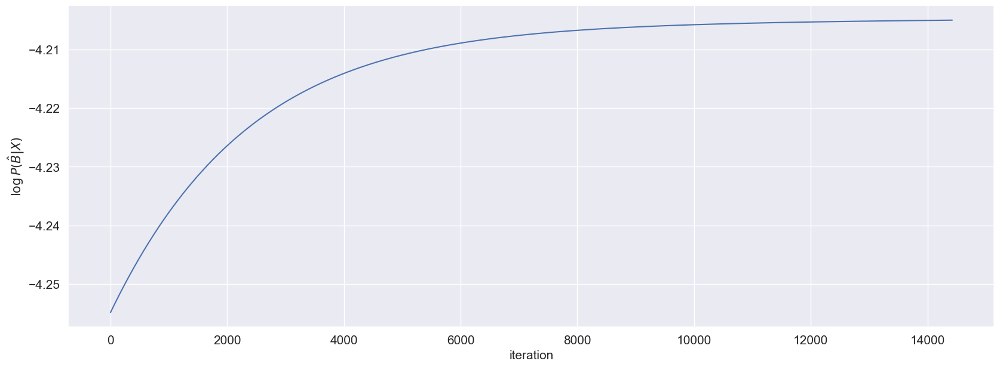

In [119]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


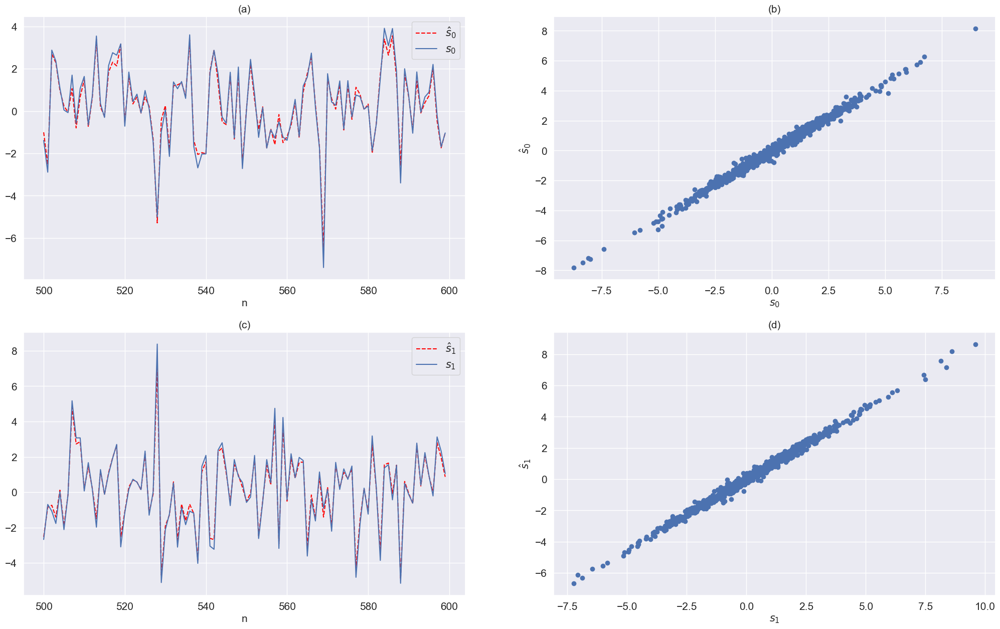

In [120]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


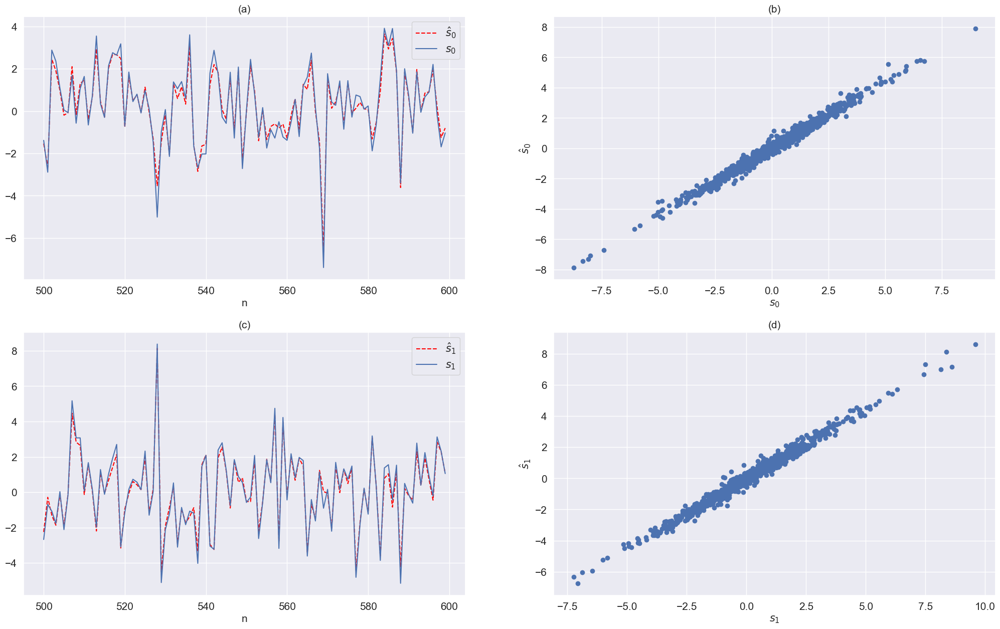

In [121]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


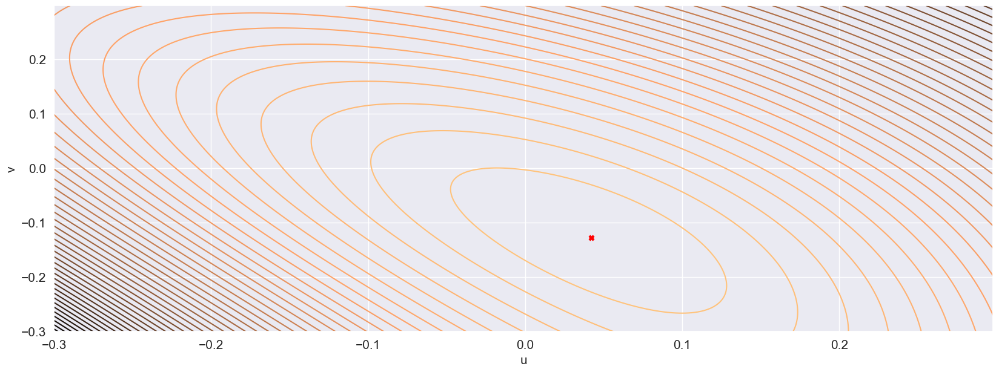

In [122]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [123]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.00589818807835687), "
 "'s_map': np.float64(0.006966300178319149), 'B_mmse': "
 "np.float64(0.12753120431408813), 'B_map': np.float64(0.15539590008506649), "
 "'max_u_v': [np.float64(0.042), np.float64(-0.128)], 'u_v_norm': "
 'np.float64(0.13471451295239129)}')


## ii.

In [124]:
# Test case
test_case='ii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-2.12206224, -1.13218572, -0.2772196 , ...,  1.40603267,
          3.06989017, -2.15950919],
        [-0.45218341,  0.24576018, -4.25206601, ...,  2.2474318 ,
         -0.33005412,  1.43724601]], shape=(2, 1000)),
 'x': array([[-2.57424565, -0.88642554, -4.52928562, ...,  3.65346447,
          2.73983605, -0.72226318],
        [ 0.83493941,  0.68897295, -1.98742321, ...,  0.42069956,
         -1.69997215,  1.7983776 ]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11954c7d0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x11954ccd0>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x11954ce10>}

#### Parse MMSE

In [125]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [126]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.45636468 -1.13288404]
 [ 0.53908735  0.93146806]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.1015611287395964
----------------------------------------------------------------------------------------------------


In [127]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-3963.696901012237)]

In [128]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.45636468, -1.13288404],
        [ 0.53908735,  0.93146806]])]

#### Parse MAP

In [129]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [130]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.55365268 -0.88310336]
 [ 0.43458491  1.12927846]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.12253243046990671
----------------------------------------------------------------------------------------------------


In [131]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-3.9681189158010417)]

In [132]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.55365268, -0.88310336],
        [ 0.43458491,  1.12927846]])]

#### Parse contour line

In [133]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


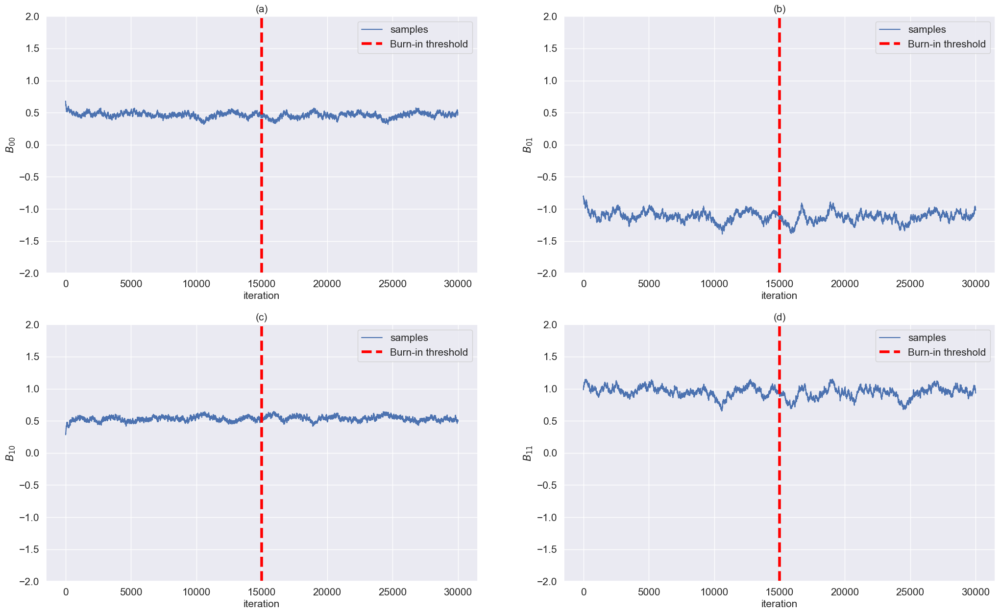

In [134]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


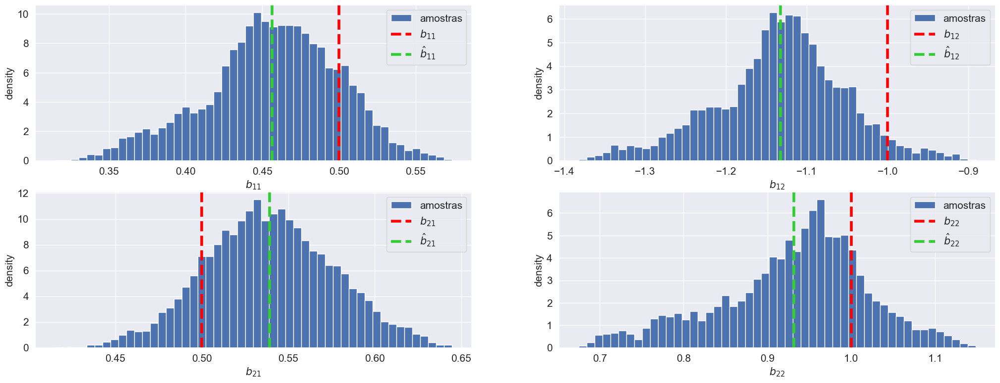

In [135]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


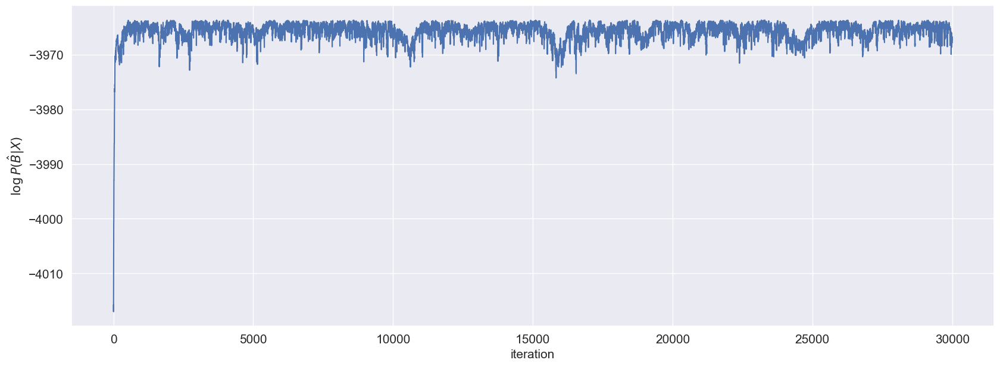

In [136]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


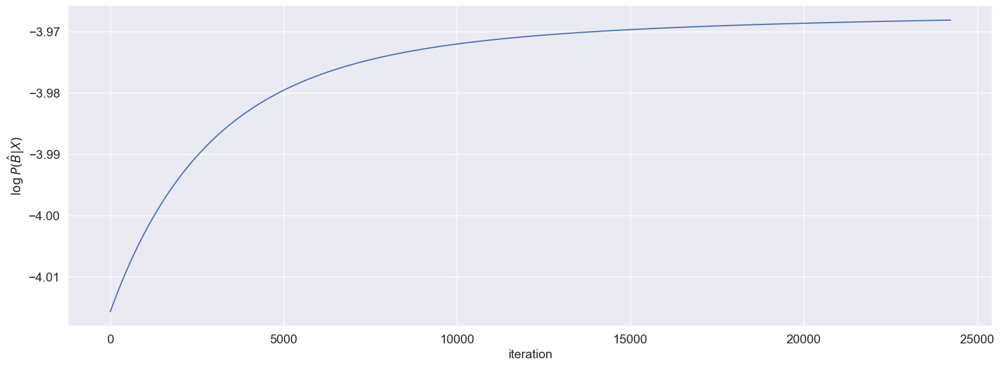

In [137]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


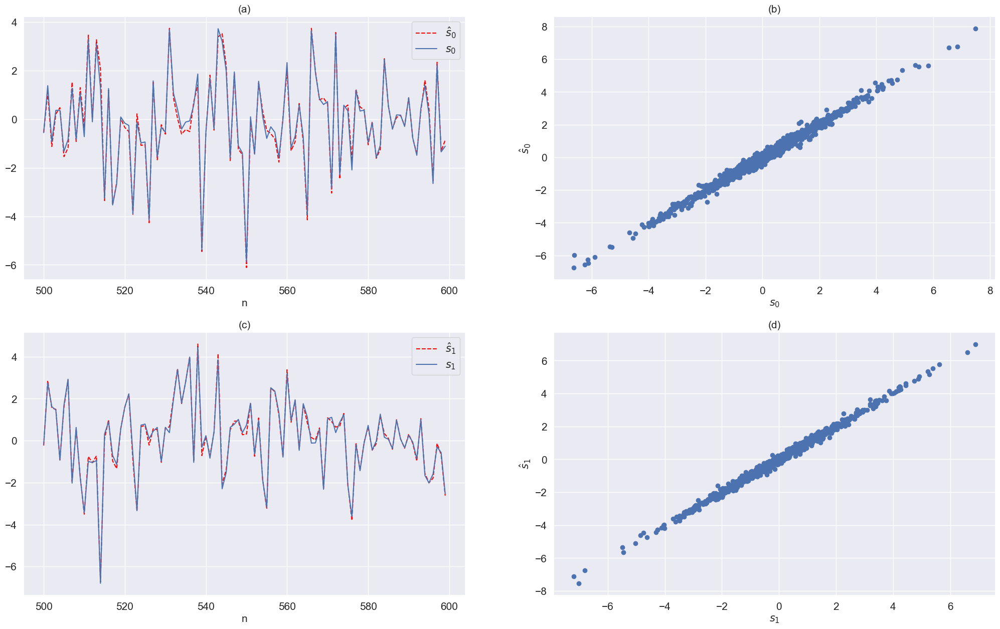

In [138]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


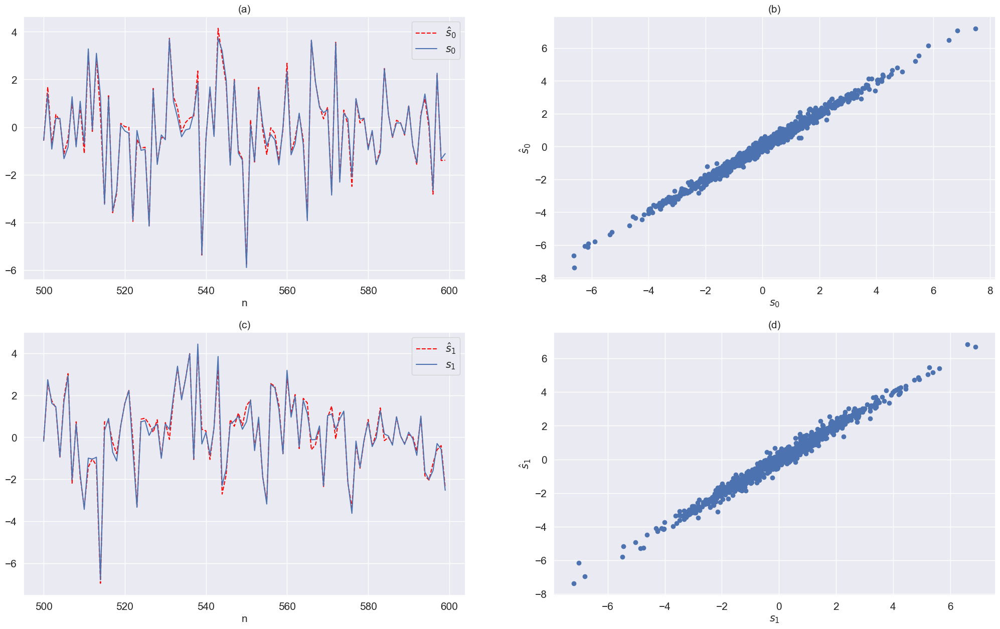

In [139]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


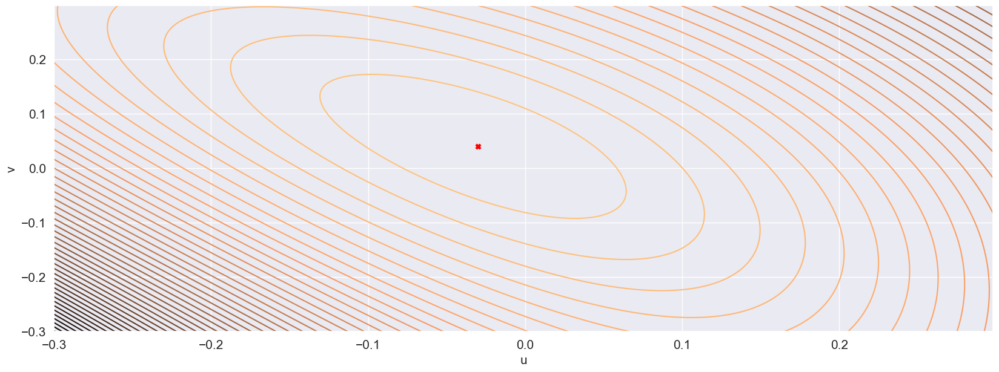

In [140]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [141]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.003765259047728241), "
 "'s_map': np.float64(0.004844609128674674), 'B_mmse': "
 "np.float64(0.1015611287395964), 'B_map': np.float64(0.12253243046990671), "
 "'max_u_v': [np.float64(-0.03), np.float64(0.04)], 'u_v_norm': "
 'np.float64(0.05)}')


## vii.

In [142]:
# Test case
test_case='vii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[ 1.05192499,  0.38169569,  2.84148201, ...,  2.97151869,
          0.19921437,  1.22139494],
        [ 1.26592132, -1.52897239,  1.28811983, ...,  2.85701456,
         -1.00502702,  1.00604107]], shape=(2, 1000)),
 'x': array([[ 2.31784631, -1.14727671,  4.12960184, ...,  5.82853325,
         -0.80581265,  2.22743601],
        [ 0.10699817, -0.95533404, -0.77668109, ..., -0.05725206,
         -0.60212069, -0.10767693]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11ccc0270>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x11ccc0380>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x11ccc0490>}

#### Parse MMSE

In [143]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [144]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.42783042 -0.96153984]
 [ 0.47575292  0.87958382]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.09332868504663219
----------------------------------------------------------------------------------------------------


In [145]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-4202.039472615029)]

In [146]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.42783042, -0.96153984],
        [ 0.47575292,  0.87958382]])]

#### Parse MAP

In [147]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [148]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.48757843 -0.80749504]
 [ 0.41118561  0.99989077]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.13431375433817877
----------------------------------------------------------------------------------------------------


In [149]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-4.206241050104472)]

In [150]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.48757843, -0.80749504],
        [ 0.41118561,  0.99989077]])]

#### Parse contour line

In [151]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


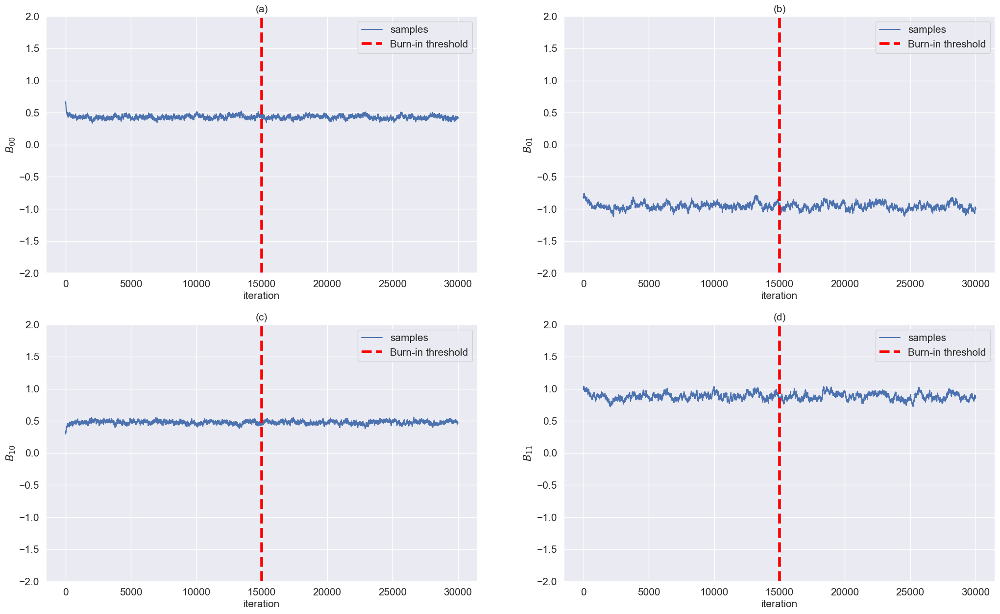

In [152]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


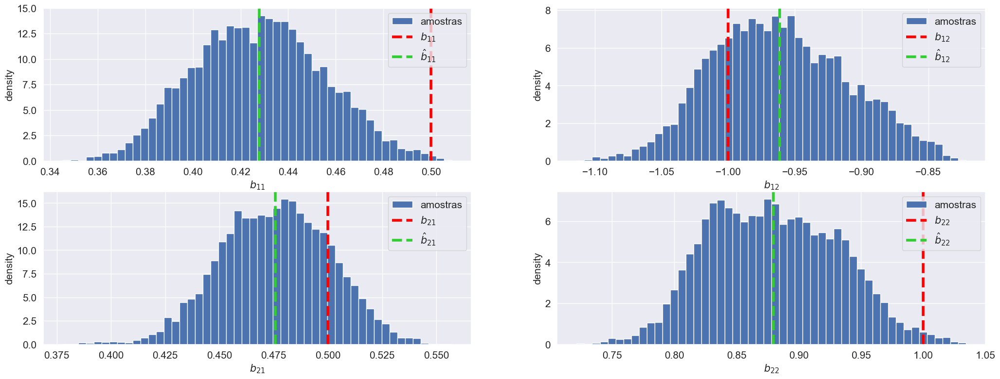

In [153]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


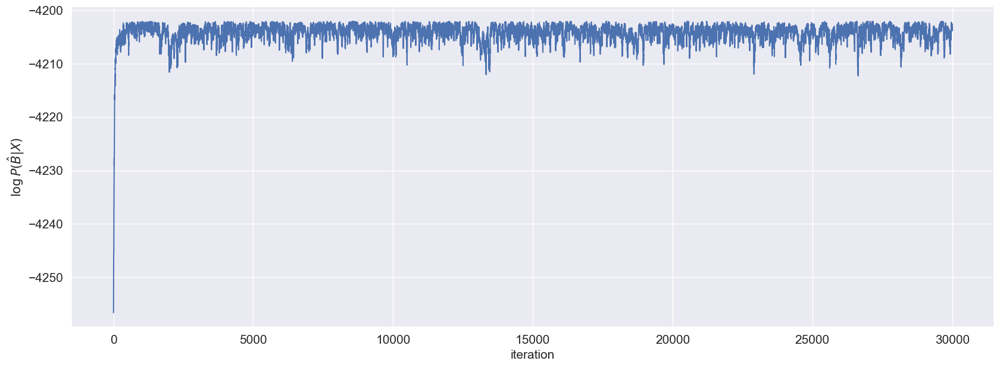

In [154]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


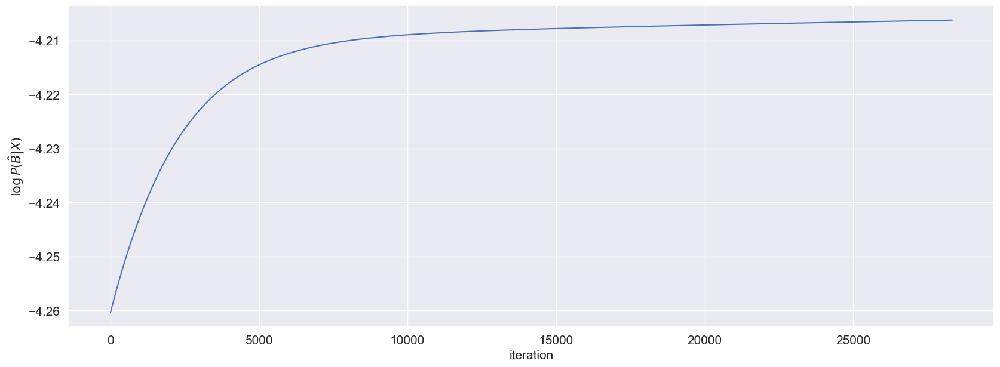

In [155]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


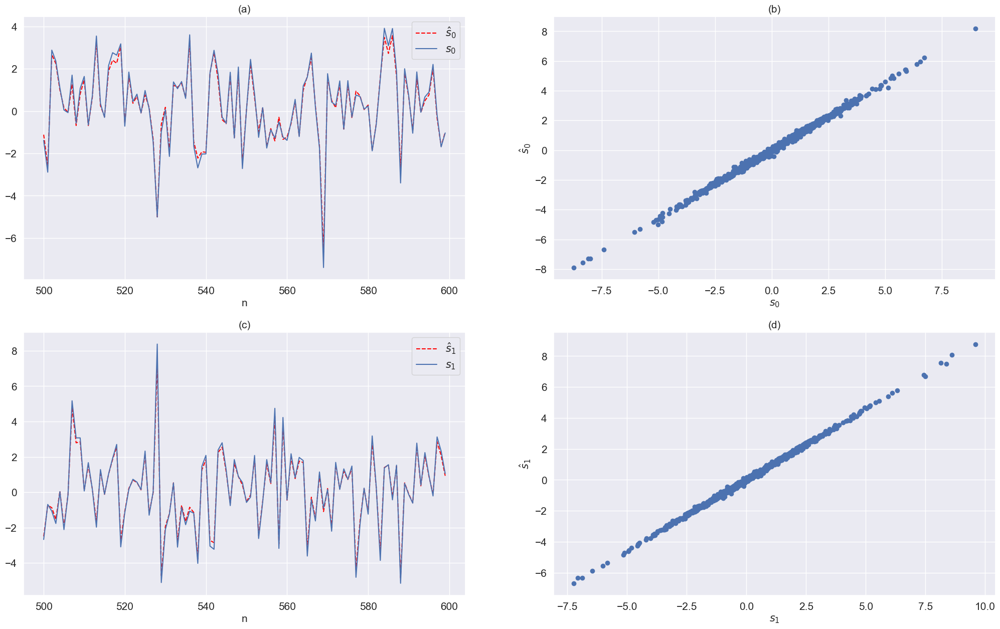

In [156]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


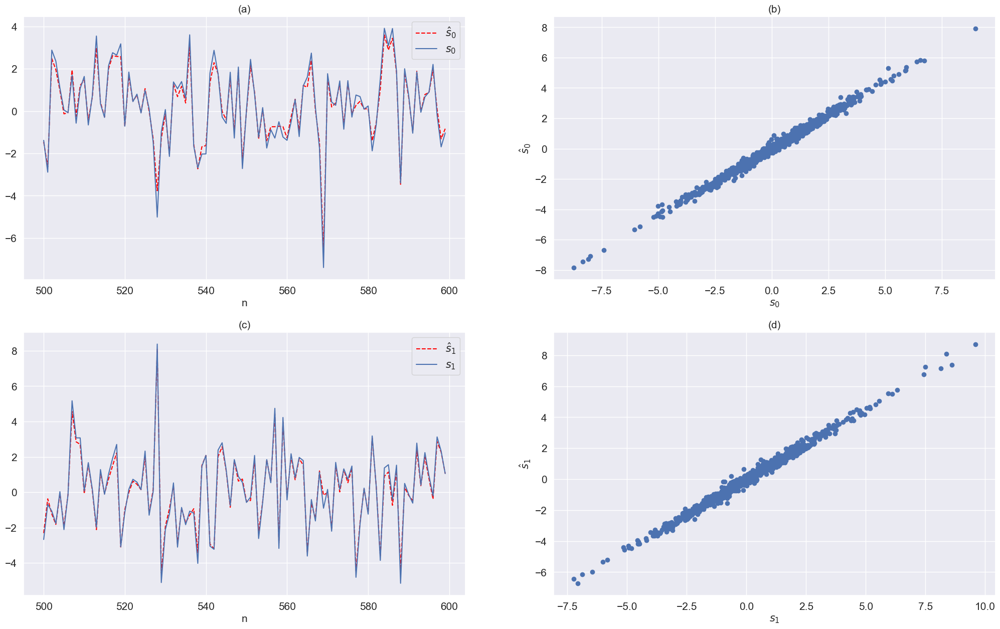

In [157]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


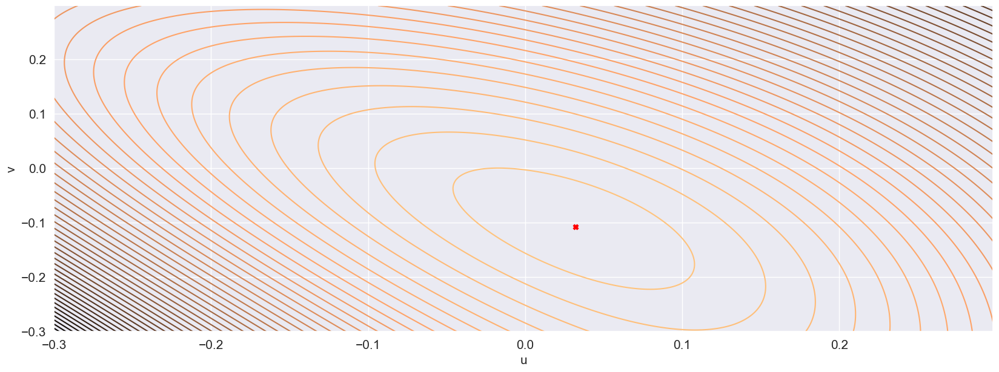

In [158]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [159]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.0044770974886829155), "
 "'s_map': np.float64(0.005952245304343655), 'B_mmse': "
 "np.float64(0.09332868504663219), 'B_map': np.float64(0.13431375433817877), "
 "'max_u_v': [np.float64(0.032), np.float64(-0.108)], 'u_v_norm': "
 'np.float64(0.11264102272262978)}')


## viii.

In [160]:
# Test case
test_case='viii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[ 1.05192499,  0.38169569,  2.84148201, ...,  2.97151869,
          0.19921437,  1.22139494],
        [ 1.26592132, -1.52897239,  1.28811983, ...,  2.85701456,
         -1.00502702,  1.00604107]], shape=(2, 1000)),
 'x': array([[ 2.31784631, -1.14727671,  4.12960184, ...,  5.82853325,
         -0.80581265,  2.22743601],
        [ 0.10699817, -0.95533404, -0.77668109, ..., -0.05725206,
         -0.60212069, -0.10767693]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x11ccc05a0>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x11ccc06b0>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x11ccc07c0>}

#### Parse MMSE

In [161]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [162]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.62489813  0.24688929]
 [-0.12546421  1.22485234]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.897127970179916
----------------------------------------------------------------------------------------------------


In [163]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-4230.420150455499)]

In [164]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.62489813,  0.24688929],
        [-0.12546421,  1.22485234]])]

#### Parse MAP

In [165]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [166]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.52180621 -0.76856556]
 [ 0.37397953  1.02016026]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.16772001055490393
----------------------------------------------------------------------------------------------------


In [167]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-4.254393783630136)]

In [168]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 0.52180621, -0.76856556],
        [ 0.37397953,  1.02016026]])]

#### Parse contour line

In [169]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


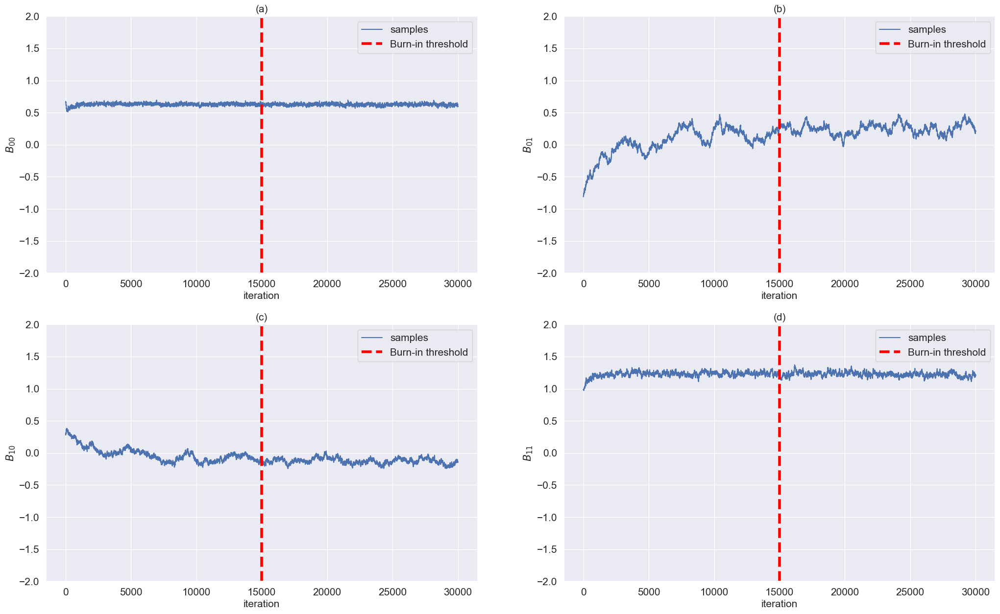

In [170]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


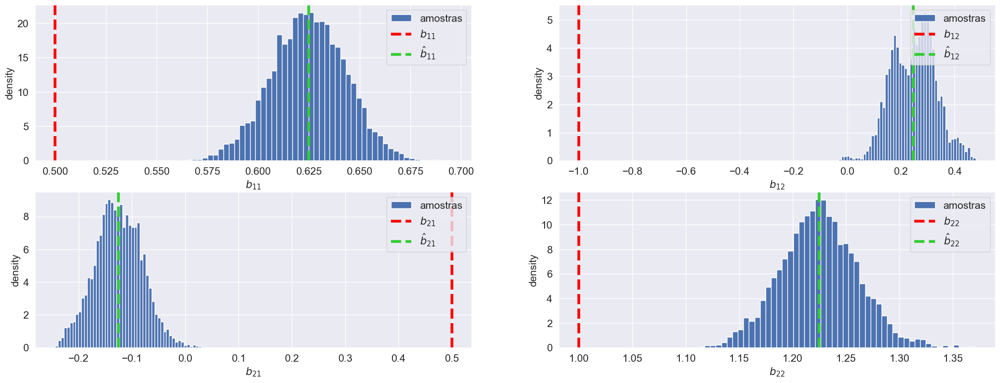

In [171]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


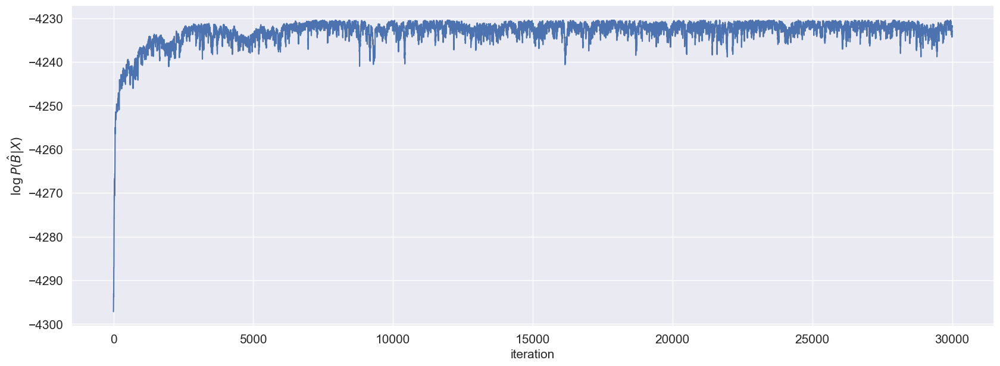

In [172]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


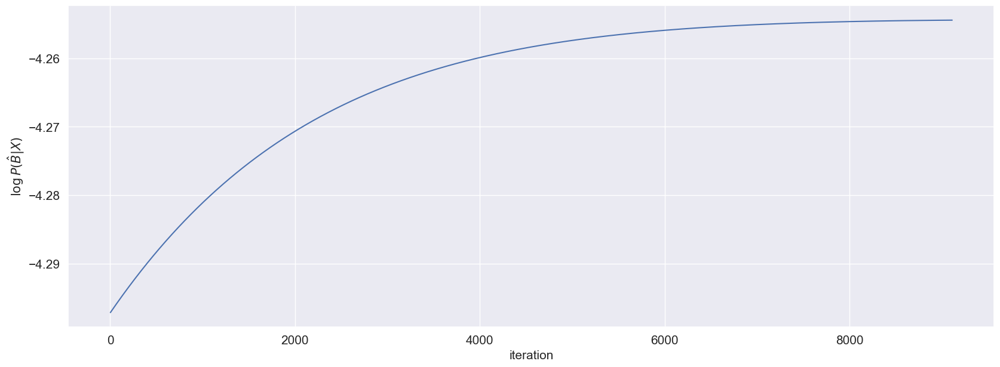

In [173]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


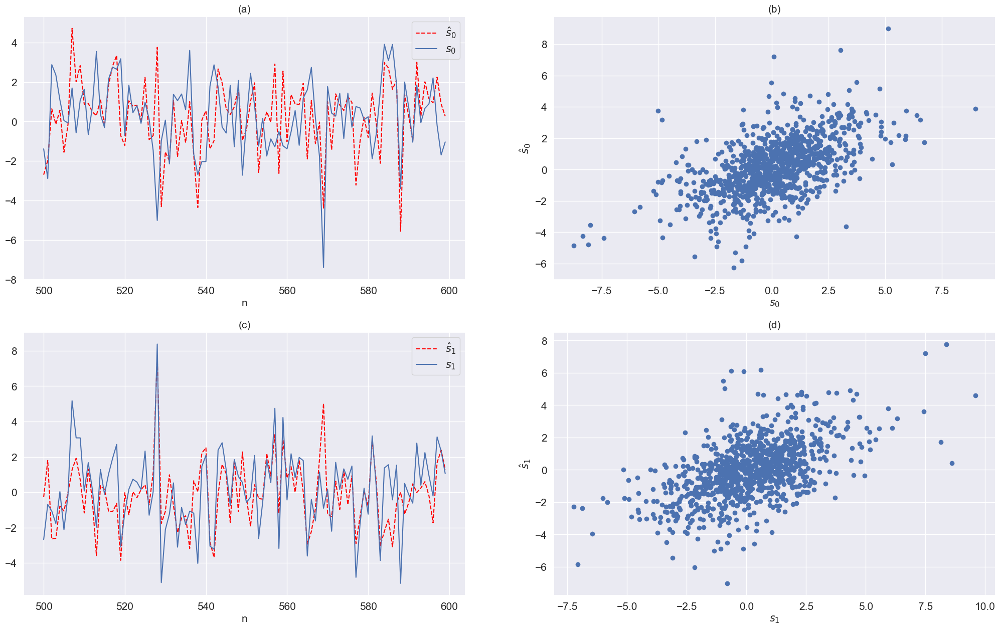

In [174]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


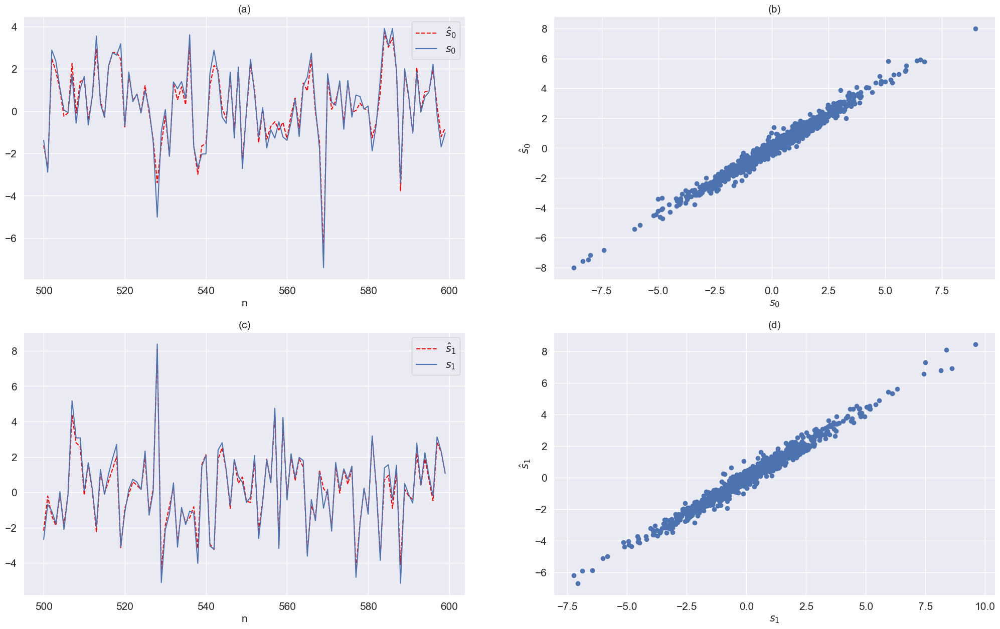

In [175]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


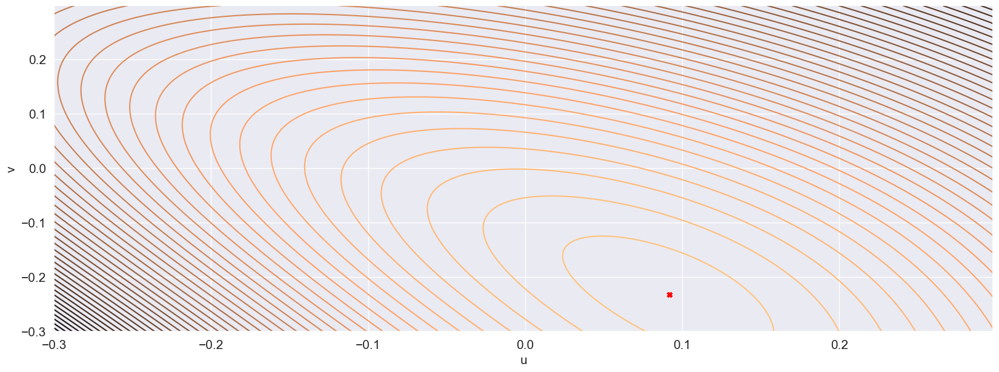

In [176]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [177]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.04066029151037766), "
 "'s_map': np.float64(0.007814126265954915), 'B_mmse': "
 "np.float64(0.897127970179916), 'B_map': np.float64(0.16772001055490393), "
 "'max_u_v': [np.float64(0.092), np.float64(-0.232)], 'u_v_norm': "
 'np.float64(0.24957563983690395)}')


## ix.

In [178]:
# Test case
test_case='ix'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-0.06066148,  0.22282508, -1.26836922, ..., -0.8019332 ,
         -0.62979004, -1.56842372],
        [-1.0760789 ,  0.64582367, -0.03023162, ...,  0.44975867,
         -0.87165405,  0.36245503]], shape=(2, 1000)),
 'x': array([[-1.13674038,  0.86864875, -1.29860084, ..., -0.35217453,
         -1.50144409, -1.20596869],
        [-0.50770871,  0.21149929,  0.6190688 , ...,  0.62584594,
         -0.12093201,  0.96543938]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x1194cbb50>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x1194cbc50>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x1194cbd50>}

#### Parse MMSE

In [179]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [180]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.48538208 -0.09721397]
 [ 0.03928159  2.95792462]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 1.527315384644766
----------------------------------------------------------------------------------------------------


In [181]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-2477.6228453306685)]

In [182]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 1.48538208, -0.09721397],
        [ 0.03928159,  2.95792462]])]

#### Parse MAP

In [183]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [184]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.23664231 -1.52618543]
 [ 0.76863351  2.33585066]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 1.0346349996466224
----------------------------------------------------------------------------------------------------


In [185]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-2.4974428103374167)]

In [186]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 1.23664231, -1.52618543],
        [ 0.76863351,  2.33585066]])]

#### Parse contour line

In [187]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


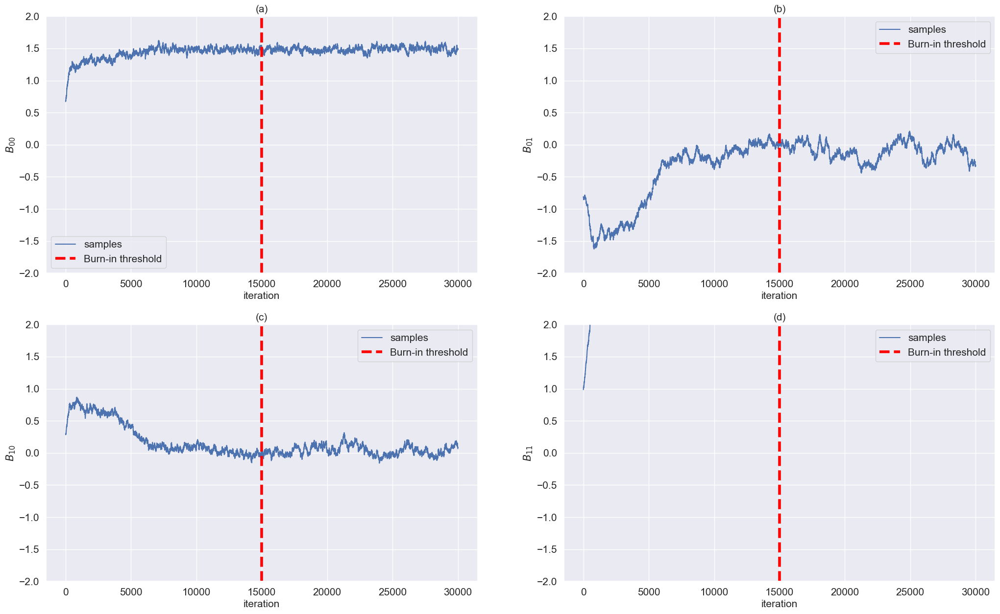

In [188]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


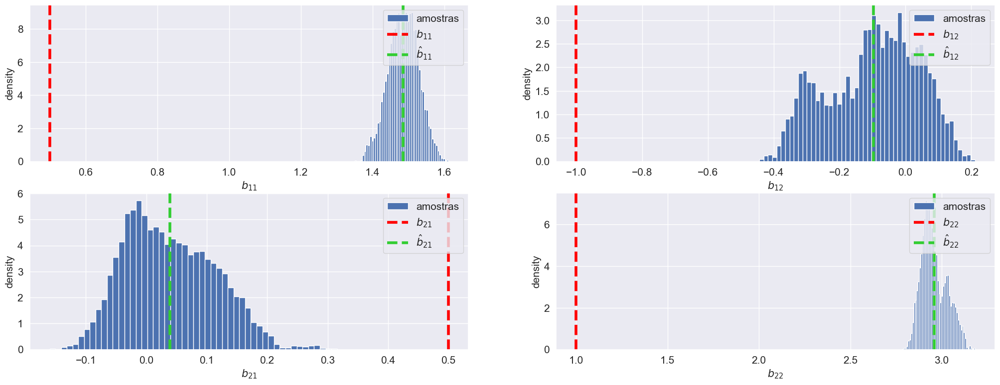

In [189]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


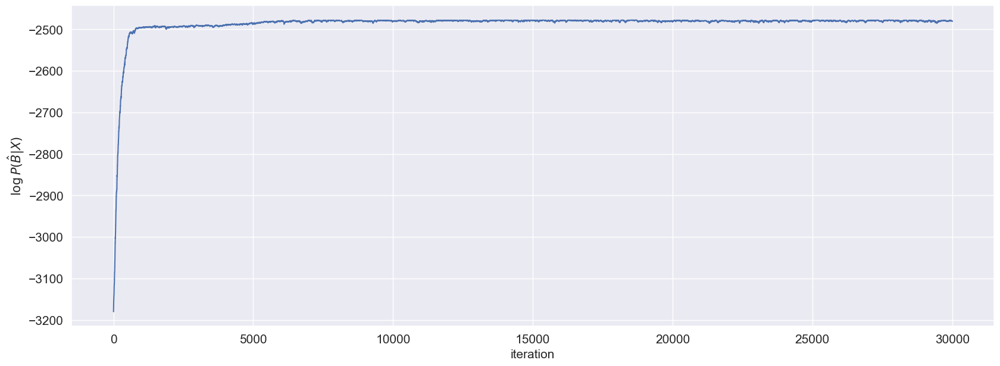

In [190]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


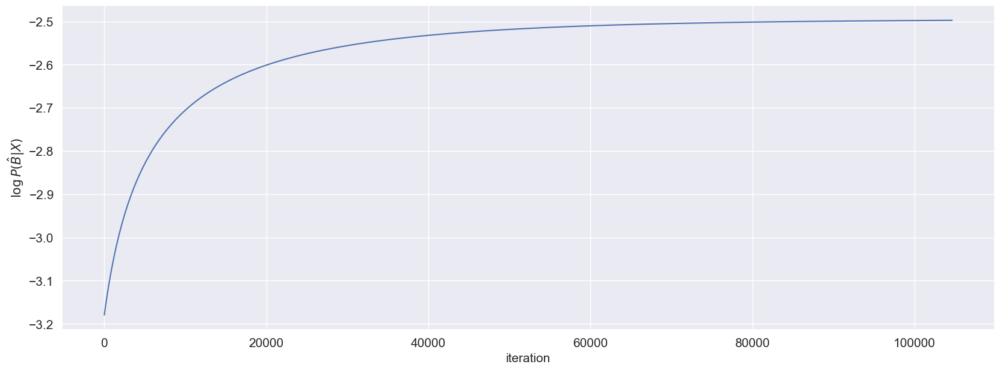

In [191]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


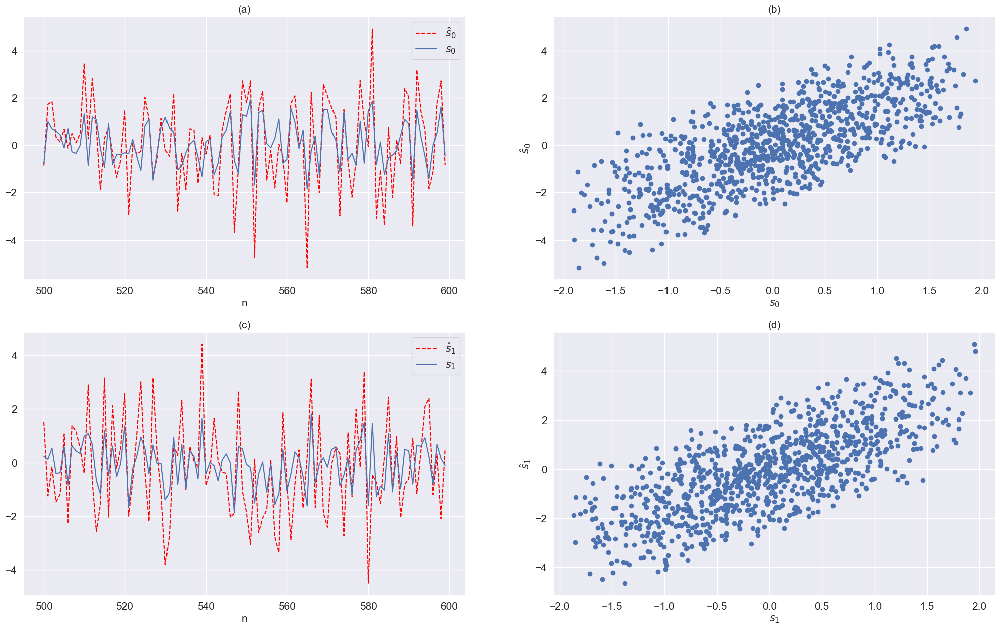

In [192]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


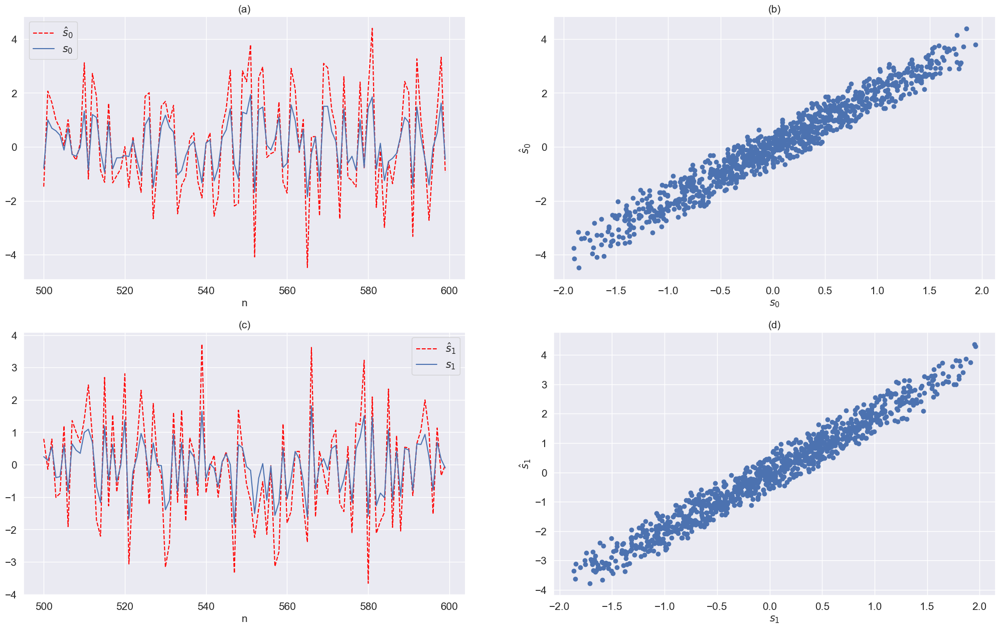

In [193]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


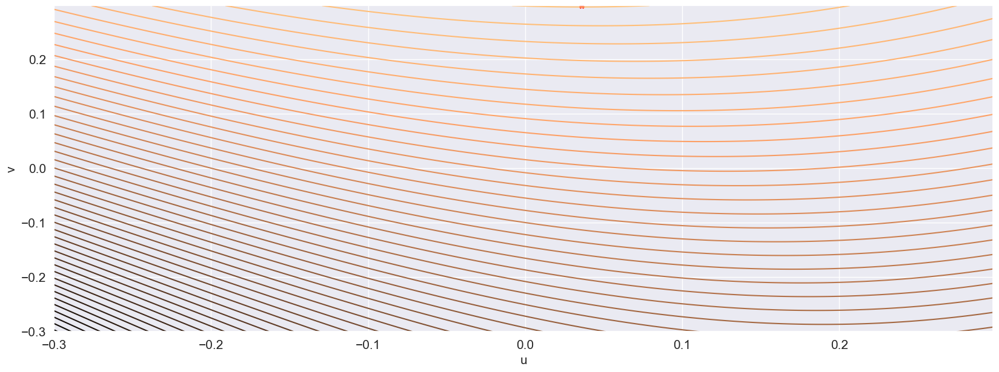

In [194]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [195]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.028170851898597044), "
 "'s_map': np.float64(0.019558346158312926), 'B_mmse': "
 "np.float64(1.527315384644766), 'B_map': np.float64(1.0346349996466224), "
 "'max_u_v': [np.float64(0.036000000000000004), np.float64(0.298)], "
 "'u_v_norm': np.float64(0.30016662039607267)}")


## x.

In [196]:
# Test case
test_case='x'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-0.06066148,  0.22282508, -1.26836922, ..., -0.8019332 ,
         -0.62979004, -1.56842372],
        [-1.0760789 ,  0.64582367, -0.03023162, ...,  0.44975867,
         -0.87165405,  0.36245503]], shape=(2, 1000)),
 'x': array([[-1.13674038,  0.86864875, -1.29860084, ..., -0.35217453,
         -1.50144409, -1.20596869],
        [-0.50770871,  0.21149929,  0.6190688 , ...,  0.62584594,
         -0.12093201,  0.96543938]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x1194cbe50>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x12beb4050>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x12beb4150>}

#### Parse MMSE

In [197]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [198]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.47655919  0.19403743]
 [-0.09168967  2.95421058]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 1.6184472679506214
----------------------------------------------------------------------------------------------------


In [199]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-2477.6505926986606)]

In [200]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 1.47655919,  0.19403743],
        [-0.09168967,  2.95421058]])]

#### Parse MAP

In [201]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [202]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.23644141 -1.5262341 ]
 [ 0.76872753  2.33532069]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 1.0343237621047936
----------------------------------------------------------------------------------------------------


In [203]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-2.4974723744123186)]

In [204]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 1.23644141, -1.5262341 ],
        [ 0.76872753,  2.33532069]])]

#### Parse contour line

In [205]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


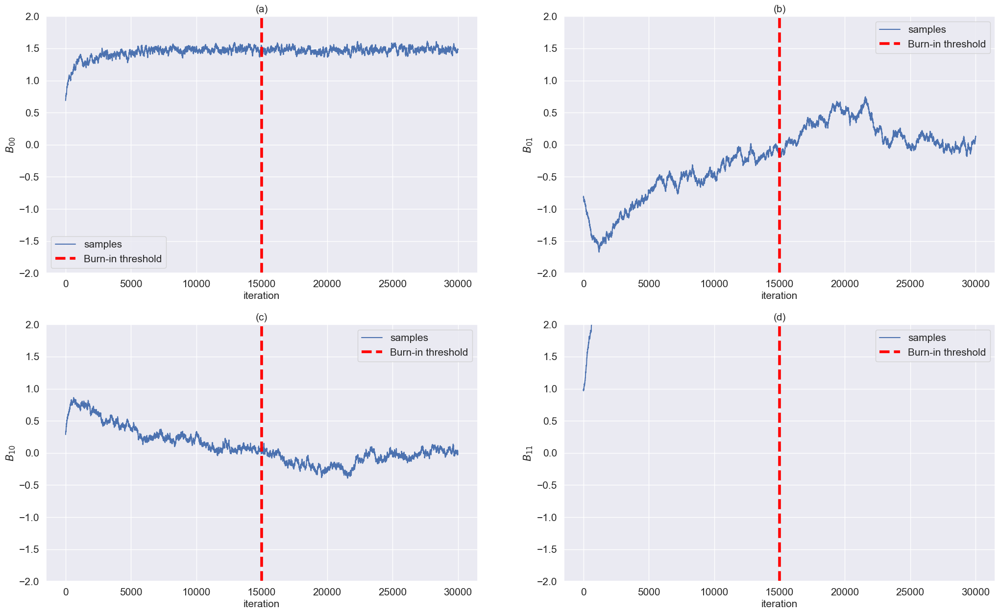

In [206]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


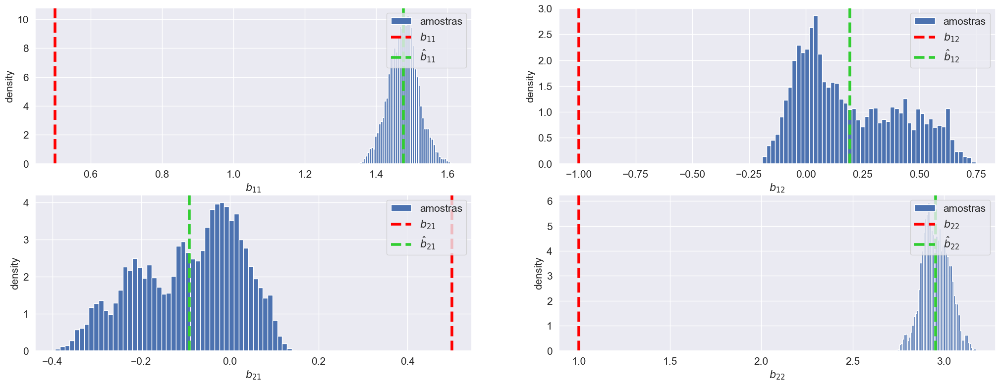

In [207]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


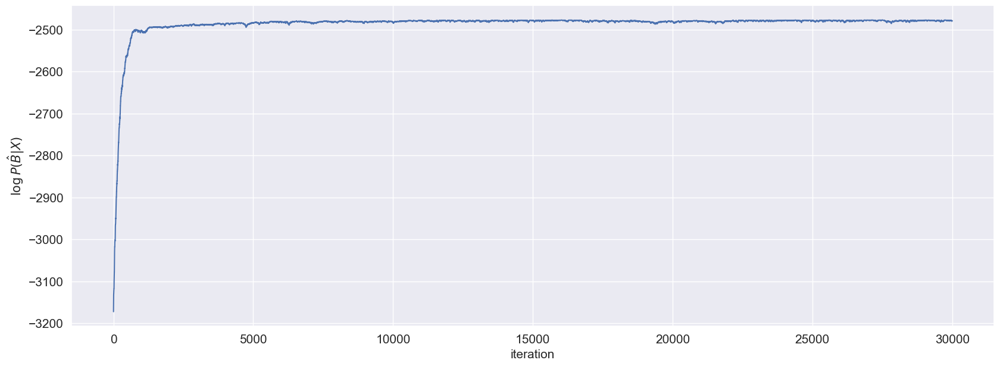

In [208]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


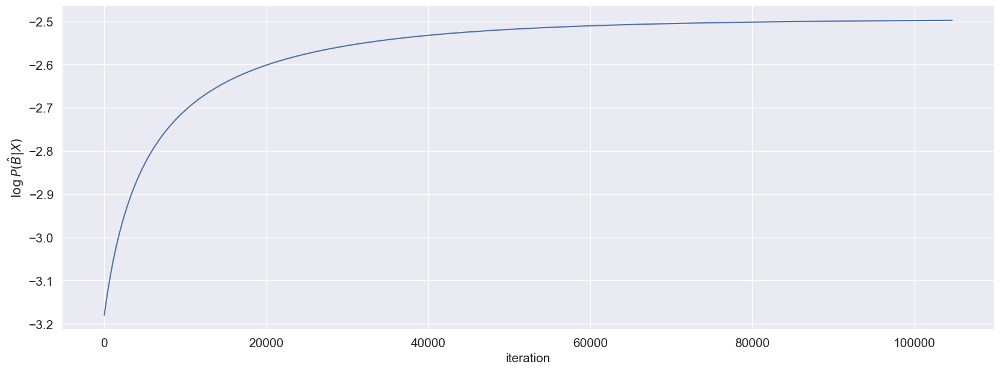

In [209]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


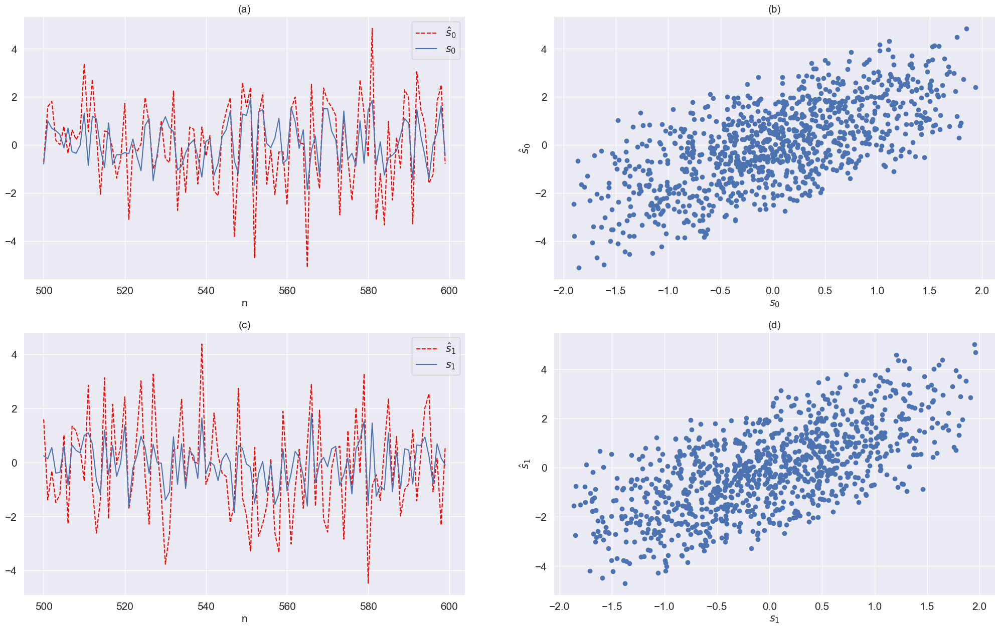

In [210]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


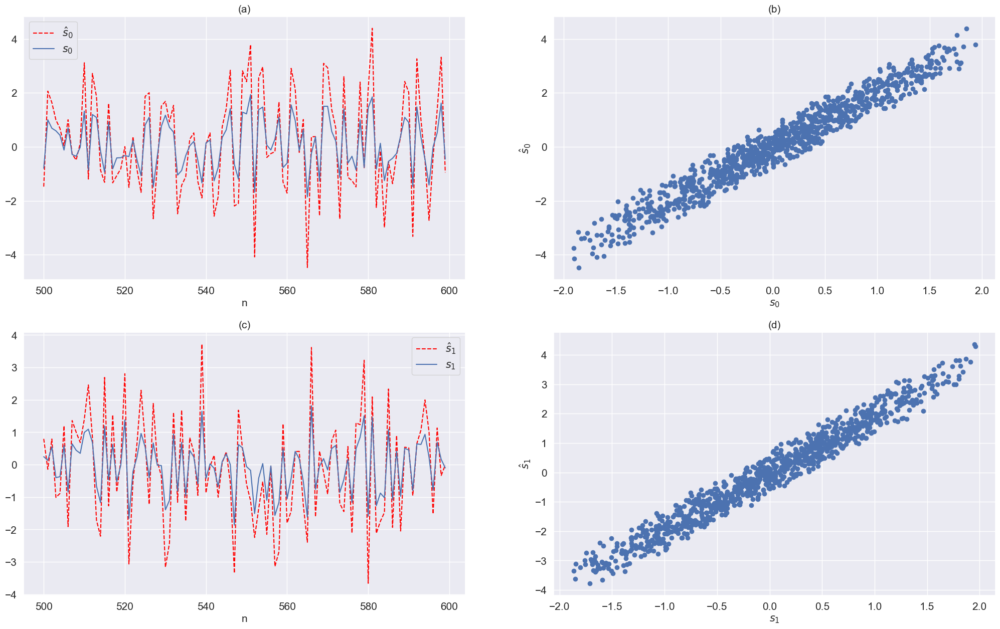

In [211]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


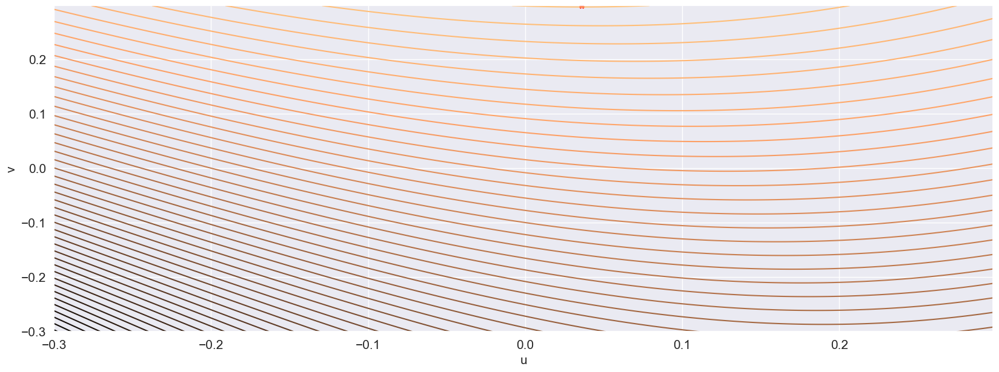

In [212]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [213]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.029745309506920954), "
 "'s_map': np.float64(0.019553277398071677), 'B_mmse': "
 "np.float64(1.6184472679506214), 'B_map': np.float64(1.0343237621047936), "
 "'max_u_v': [np.float64(0.036000000000000004), np.float64(0.298)], "
 "'u_v_norm': np.float64(0.30016662039607267)}")


## xi.

In [214]:
# Test case
test_case='xi'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-0.06066148,  0.22282508, -1.26836922, ..., -0.8019332 ,
         -0.62979004, -1.56842372],
        [-1.0760789 ,  0.64582367, -0.03023162, ...,  0.44975867,
         -0.87165405,  0.36245503]], shape=(2, 1000)),
 'x': array([[-1.13674038,  0.86864875, -1.29860084, ..., -0.35217453,
         -1.50144409, -1.20596869],
        [-0.50770871,  0.21149929,  0.6190688 , ...,  0.62584594,
         -0.12093201,  0.96543938]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x119393a70>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x119393b60>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x119393c50>}

#### Parse MMSE

In [215]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [216]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 0.9953292  -1.67079417]
 [ 0.91691366  1.79918066]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.7766138210598549
----------------------------------------------------------------------------------------------------


In [217]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-2600.584312323588)]

In [218]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 0.9953292 , -1.67079417],
        [ 0.91691366,  1.79918066]])]

#### Parse MAP

In [219]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [220]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.18568507 -1.36473151]
 [ 0.7650392   1.98112469]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.808960945512001
----------------------------------------------------------------------------------------------------


In [221]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-2.608301727516015)]

In [222]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 1.18568507, -1.36473151],
        [ 0.7650392 ,  1.98112469]])]

#### Parse contour line

In [223]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


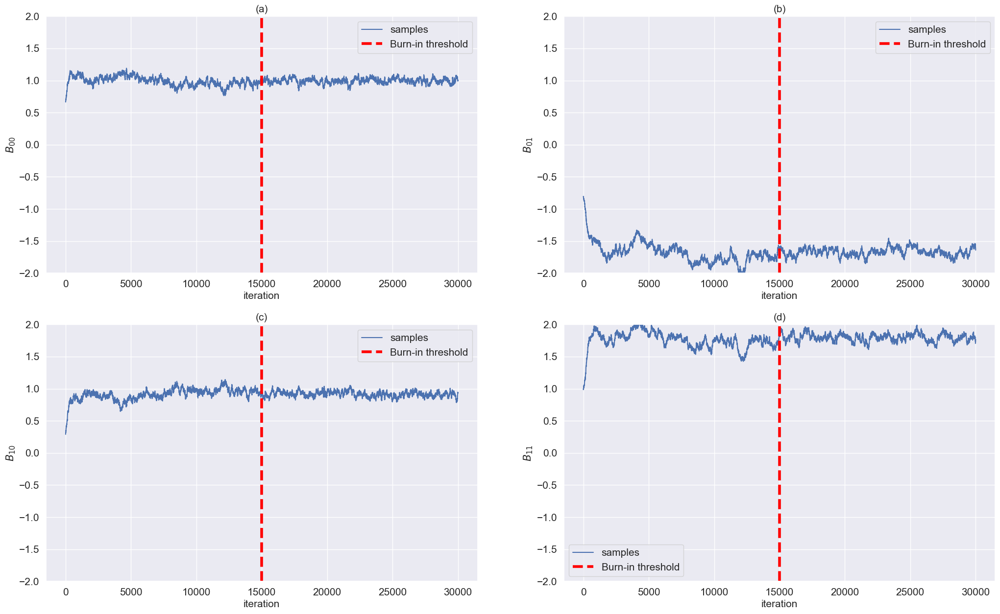

In [224]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


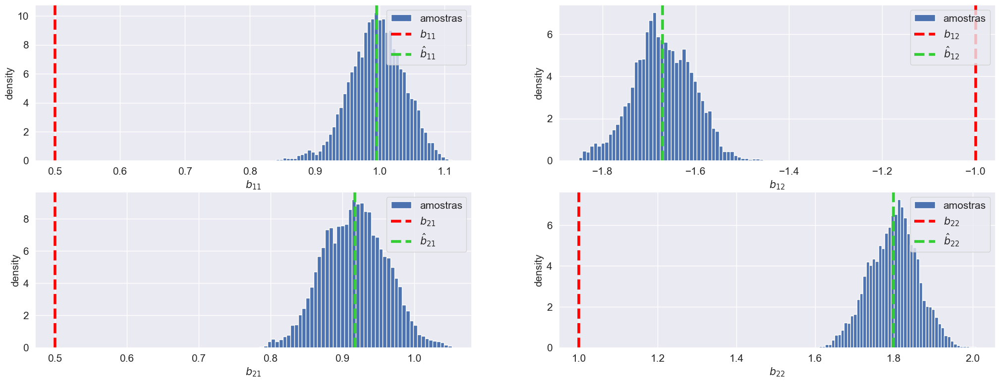

In [225]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


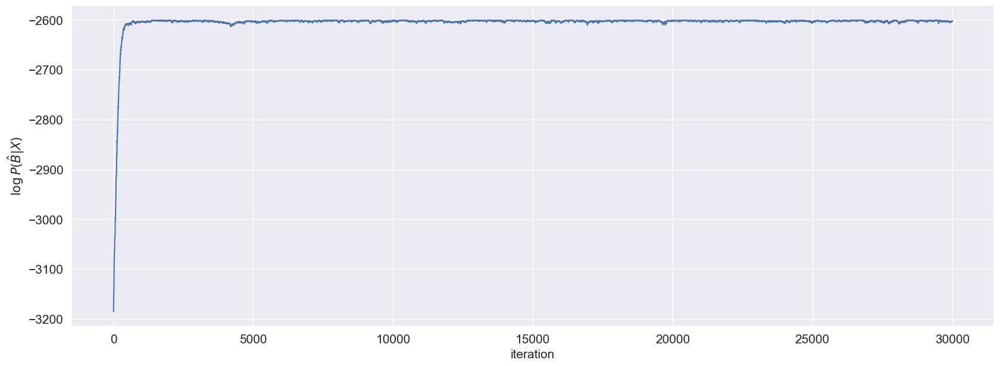

In [226]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


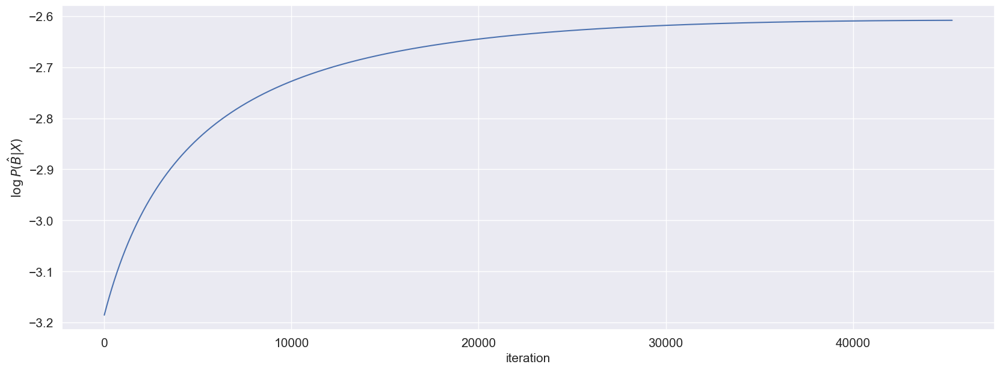

In [227]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


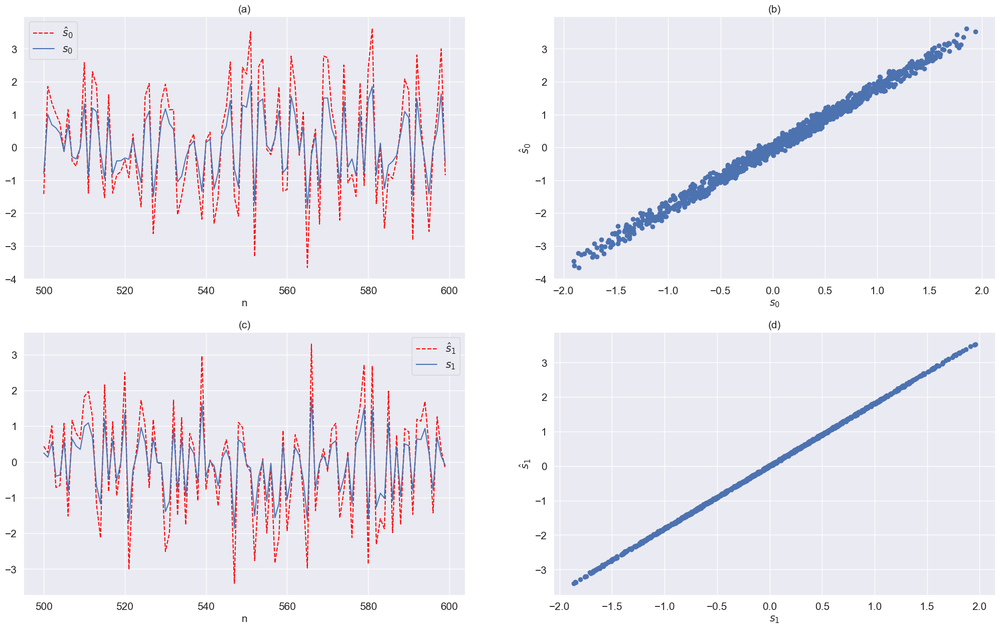

In [228]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


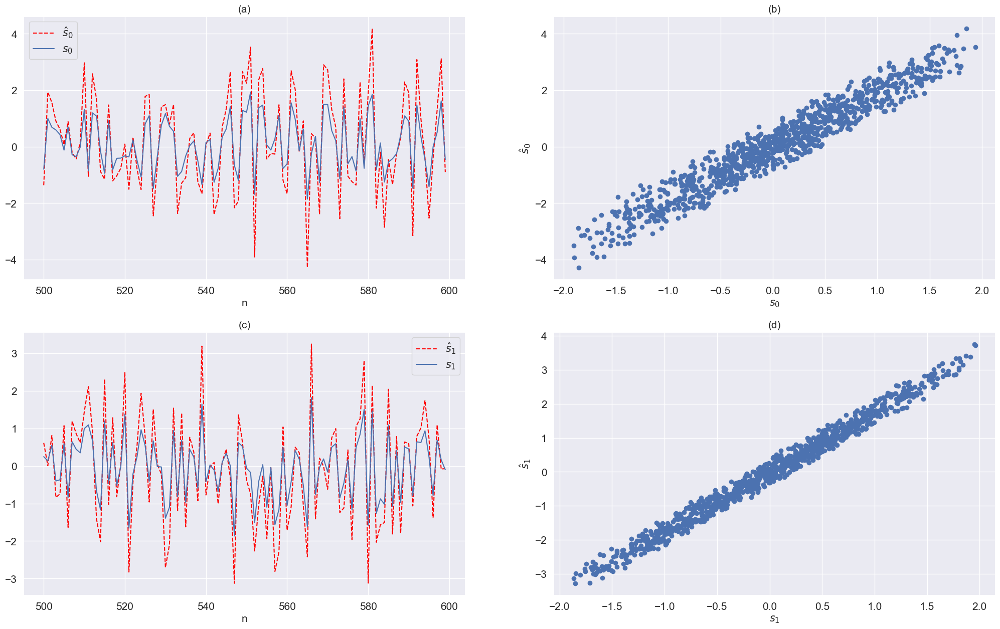

In [229]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


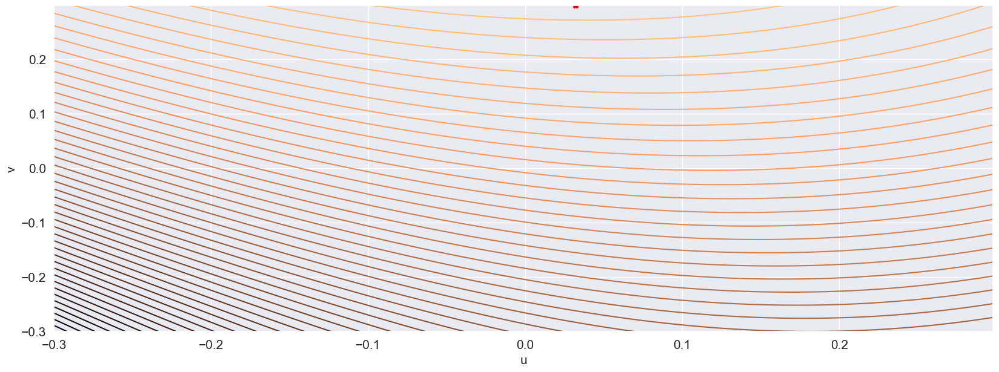

In [230]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [231]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.015302203971202457), "
 "'s_map': np.float64(0.01661245160764319), 'B_mmse': "
 "np.float64(0.7766138210598549), 'B_map': np.float64(0.808960945512001), "
 "'max_u_v': [np.float64(0.032), np.float64(0.298)], 'u_v_norm': "
 'np.float64(0.2997131962393381)}')


## xii.

In [232]:
# Test case
test_case='xii'
test_case_results = raw_results['results'][test_case]

# Get directory for saving test case graphs
test_case_dir = realization_dir / test_case
if not test_case_dir.is_dir():
    test_case_dir.mkdir()
    
test_case_results

{'s': array([[-0.06066148,  0.22282508, -1.26836922, ..., -0.8019332 ,
         -0.62979004, -1.56842372],
        [-1.0760789 ,  0.64582367, -0.03023162, ...,  0.44975867,
         -0.87165405,  0.36245503]], shape=(2, 1000)),
 'x': array([[-1.13674038,  0.86864875, -1.29860084, ..., -0.35217453,
         -1.50144409, -1.20596869],
        [-0.50770871,  0.21149929,  0.6190688 , ...,  0.62584594,
         -0.12093201,  0.96543938]], shape=(2, 1000)),
 'mmse_estimator': <src.estimator.MMSEMetropolisHastingsEstimator at 0x119393d40>,
 'map_estimator': <src.estimator.MAPGradientAscentEstimator at 0x119393e30>,
 'posteriori_grid': <src.contour_line.PosteriorContourLines at 0x119393f20>}

#### Parse MMSE

In [233]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
mmse_estimator = test_case_results['mmse_estimator']
B_est_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['B_est']
s_est_mmse = B_est_mmse@test_case_results['x']
samples = mmse_estimator.mcmc_results[analyzed_model_idx]['samples']
valid_samples = mmse_estimator.mcmc_results[analyzed_model_idx]['valid_samples']
logs_mmse = mmse_estimator.mcmc_results[analyzed_model_idx]['logs']

In [234]:
# Get error norm for MMSE estimator
mmse_error_norm = np.linalg.norm(
    np.subtract(
        B_est_mmse,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_mmse))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(mmse_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.42555071e+00 -1.53625478e-02]
 [ 6.82818456e-04  2.33902352e+00]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 1.2439383699654603
----------------------------------------------------------------------------------------------------


In [235]:
# Posteriors
[r['max_posterior'] for r in mmse_estimator.mcmc_results]

[np.float64(-2617.780869259914)]

In [236]:
[r['B_est'] for r in mmse_estimator.mcmc_results]

[array([[ 1.42555071e+00, -1.53625478e-02],
        [ 6.82818456e-04,  2.33902352e+00]])]

#### Parse MAP

In [237]:
# Get results for analyzed model (best model by default)
analyzed_model_idx = 0
map_estimator = test_case_results['map_estimator']
B_est_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['B_est']
s_est_map = B_est_map@test_case_results['x']
logs_map = map_estimator.gradient_ascent_results[analyzed_model_idx]['logs']

In [238]:
# Get error norm for MMSE estimator
map_error_norm = np.linalg.norm(
    np.subtract(
        B_est_map,
        np.linalg.inv(A)
    )
)/np.linalg.norm(np.linalg.inv(A))

print('-'*100)
print('Estimated B:\n{}'.format(B_est_map))
print('True B:\n{}'.format(np.linalg.inv(A)))
print('Error norm: {}'.format(map_error_norm))
print('-'*100)

----------------------------------------------------------------------------------------------------
Estimated B:
[[ 1.19050634 -1.27339418]
 [ 0.73367394  1.91012019]]
True B:
[[ 0.5 -1. ]
 [ 0.5  1. ]]
Error norm: 0.7574868087962033
----------------------------------------------------------------------------------------------------


In [239]:
# Posteriors
[r['max_posterior'] for r in map_estimator.gradient_ascent_results]

[np.float64(-2.692297951114629)]

In [240]:
[r['B_est'] for r in map_estimator.gradient_ascent_results]

[array([[ 1.19050634, -1.27339418],
        [ 0.73367394,  1.91012019]])]

#### Parse contour line

In [241]:
c_lines = test_case_results['posteriori_grid']

### Plot sampled coefficients stochastic process - Markov Chain evolution

----------------------------------------------------------------------------------------------------
Evolution of sampled coefficients
(a) B00
(b) B01
(c) B10
(d) B11
----------------------------------------------------------------------------------------------------


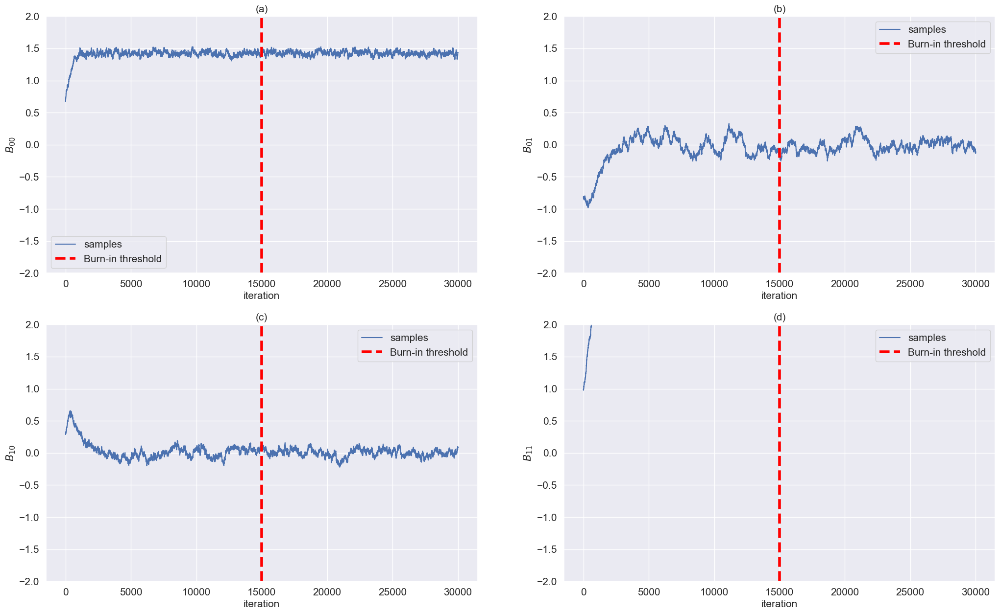

In [242]:
MCMCGraphPlotter.evolution_of_sampled_coefficients(
    samples=samples,
    estimator=mmse_estimator,
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    ylims=(-2,2)
)

### Plot Marginal Posteriors for Coefficients - Post-burn-in

----------------------------------------------------------------------------------------------------
(a) B11
(b) B12
(c) B21
(d) B22
----------------------------------------------------------------------------------------------------


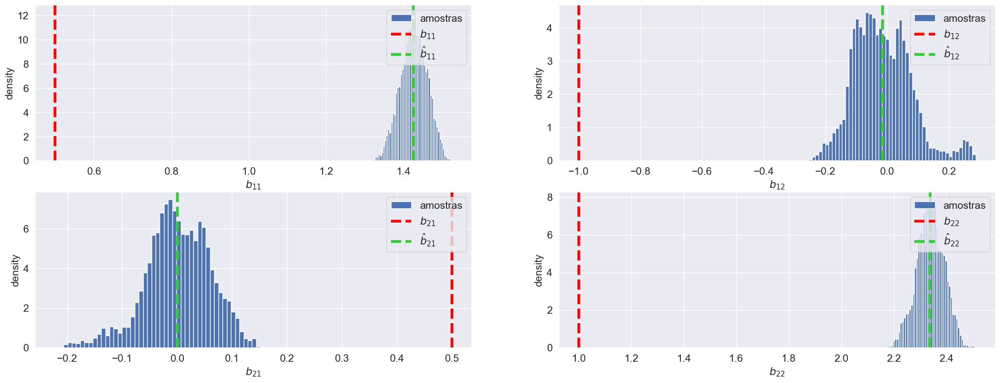

In [243]:
MCMCGraphPlotter.steady_state_marginal_distributions(
    valid_samples=valid_samples,
    nbins=50,
    B_est=B_est_mmse,
    B_true=np.linalg.inv(A),
    save_dir=test_case_dir if SAVE_GRAPHS else None,
    # xlims=(-2,2),
    # ylims=(0,10)
)

### Plot evolution of log-posterior

#### MMSE

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MMSE
----------------------------------------------------------------------------------------------------


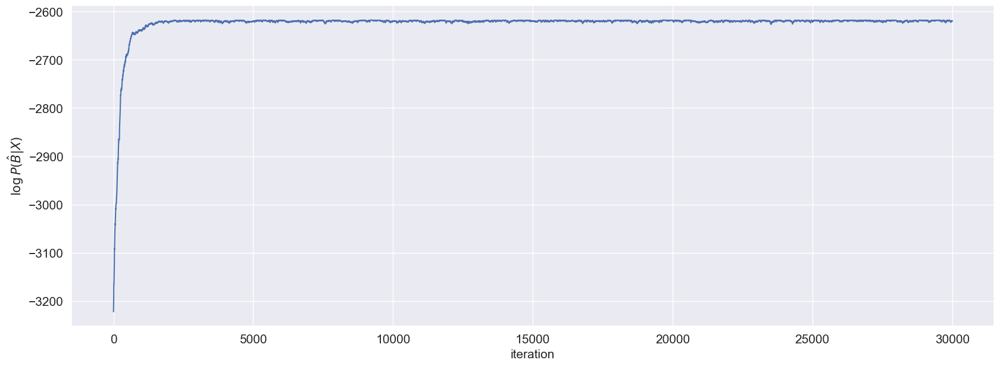

In [244]:
MCMCGraphPlotter.evolution_log_posterior(
    logs=logs_mmse,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### 1.3.7.2 MAP

----------------------------------------------------------------------------------------------------
Evolution of log-posterior - MAP
----------------------------------------------------------------------------------------------------


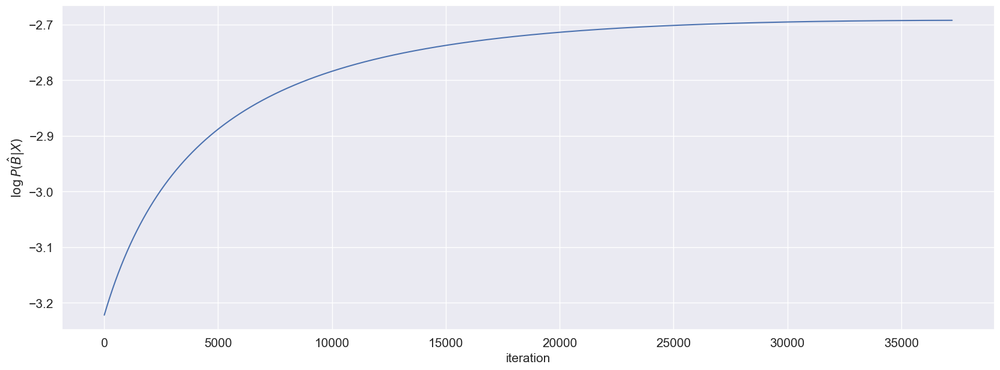

In [245]:
MAPGradientAscentGraphPlotter.evolution_log_posterior(
    logs=logs_map,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot source separation results

#### MMSE

####################################################################################################
SOURCE SEPARATION RESULTS - MMSE
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


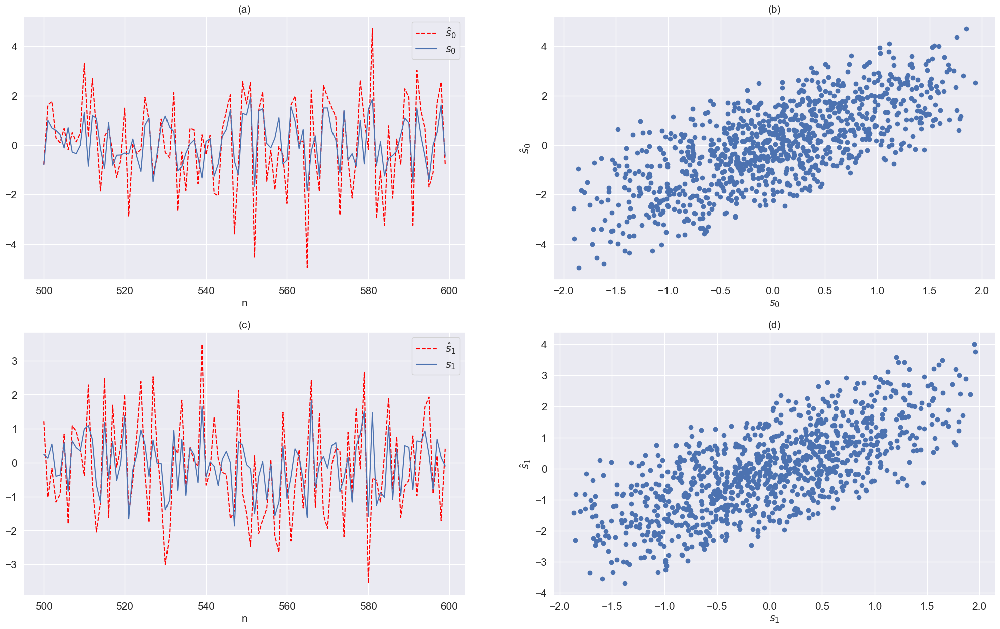

In [246]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS

MCMCGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_mmse,
    s=test_case_results['s'],
    s_est=s_est_mmse,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

#### MAP

####################################################################################################
SOURCE SEPARATION RESULTS - MAP
----------------------------------------------------------------------------------------------------
(a) Time series - true values and estimates - coefficient s0
(b) Scatter plot - true values and estimates - coefficient s0
(c) Time series - true values and estimates - coefficient s1
(d) Scatter plot - true values and estimates - coefficient s1
####################################################################################################


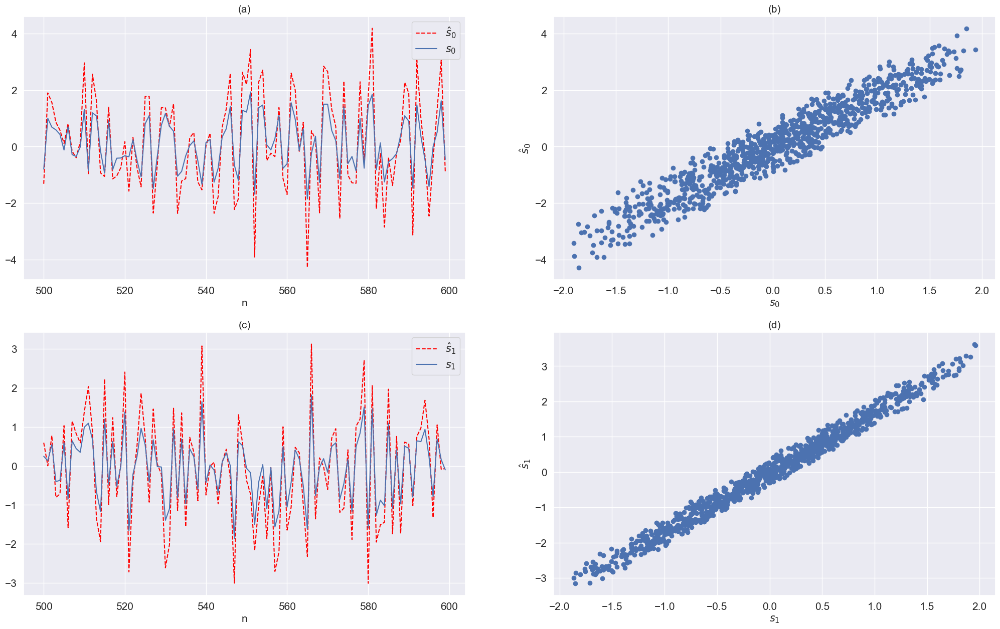

In [247]:
NPOINTS=100
PLOT_START=NOBS//2
PLOT_END=PLOT_START+NPOINTS


MAPGradientAscentGraphPlotter.source_separation_results(
    plot_start=PLOT_START,
    plot_end=PLOT_END,
    B_est=B_est_map,
    s=test_case_results['s'],
    s_est=s_est_map,
    x=test_case_results['x'],
    nobs=NOBS,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Plot 2D Contours

----------------------------------------------------------------------------------------------------
Normalized log-posterior (contour lines)
----------------------------------------------------------------------------------------------------


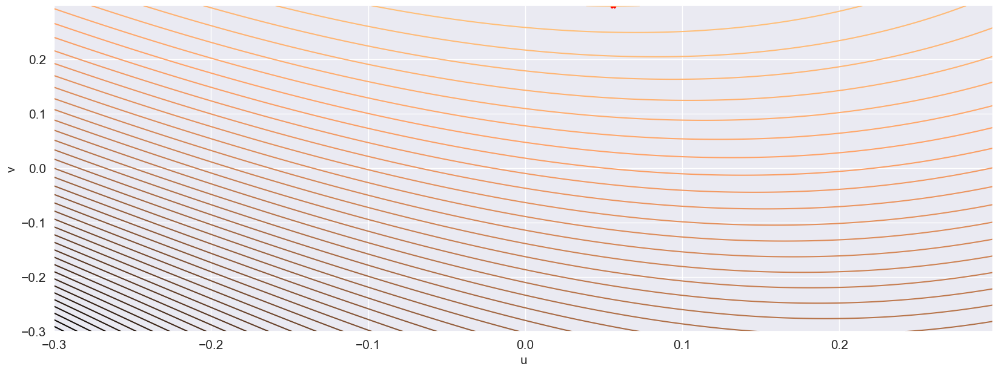

In [248]:
# 2-D Contour Lines
ContourLineGraphPlotter.plot_2D_contours(
    u_vec=c_lines.u_vec,
    v_vec=c_lines.v_vec,
    z=c_lines.posterior_grid,
    max_post_point=c_lines.max_post_point,
    save_dir=test_case_dir if SAVE_GRAPHS else None
)

### Estimation Errors

In [249]:
# Error norm - MMSE
err_mmse=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_mmse)
)/np.size(test_case_results['s'])

# Error norm - MAP
err_map=np.linalg.norm(
    np.subtract(test_case_results['s'], s_est_map)
)/np.size(test_case_results['s'])

# Errors dict
err = {
    's_mmse': err_mmse,
    's_map': err_map,
    'B_mmse': mmse_error_norm,
    'B_map': map_error_norm,
    'max_u_v': [c_lines.u_max, c_lines.v_max],
    'u_v_norm': np.linalg.norm([c_lines.u_max, c_lines.v_max])
}

# Log error
errors[test_case] = err

pprint.pp('Norma do erro de estimação: {}'.format(err))

("Norma do erro de estimação: {'s_mmse': np.float64(0.02467390474408427), "
 "'s_map': np.float64(0.016022275124760506), 'B_mmse': "
 "np.float64(1.2439383699654603), 'B_map': np.float64(0.7574868087962033), "
 "'max_u_v': [np.float64(0.056), np.float64(0.298)], 'u_v_norm': "
 'np.float64(0.3032160945596391)}')


## Errors

In [250]:
with (realization_dir/'errors.pkl').open('wb') as f:
        dill.dump(errors, f)

pprint.pp(errors)

{'i': {'s_mmse': np.float64(0.0034497835647905495),
       's_map': np.float64(0.004846124252209122),
       'B_mmse': np.float64(0.09227941920619714),
       'B_map': np.float64(0.12256956798974478),
       'max_u_v': [np.float64(-0.03), np.float64(0.04)],
       'u_v_norm': np.float64(0.05)},
 'ii': {'s_mmse': np.float64(0.003765259047728241),
        's_map': np.float64(0.004844609128674674),
        'B_mmse': np.float64(0.1015611287395964),
        'B_map': np.float64(0.12253243046990671),
        'max_u_v': [np.float64(-0.03), np.float64(0.04)],
        'u_v_norm': np.float64(0.05)},
 'iii': {'s_mmse': np.float64(0.0018988974676508628),
         's_map': np.float64(0.004257285549061974),
         'B_mmse': np.float64(0.052724823462259846),
         'B_map': np.float64(0.10909924046815345),
         'max_u_v': [np.float64(-0.026000000000000002), np.float64(0.034)],
         'u_v_norm': np.float64(0.0428018691180654)},
 'iv': {'s_mmse': np.float64(0.03731100301339054),
        's_ma